<a href="https://colab.research.google.com/github/yaroslavkarpenko701/DA-python-portfolio/blob/main/Exploratory_data_analysis_for_online_store.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [91]:
from google.colab import drive
drive.mount("/content/drive/")

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [92]:
%cd /content/drive/MyDrive/for_course_DA/Final_project/

/content/drive/MyDrive/for_course_DA/Final_project


In [93]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#1) Data overview

In [94]:
df_countries = pd.read_csv("countries.csv")
df_products = pd.read_csv("products.csv")
df_events = pd.read_csv("events.csv")

In [95]:
df_countries.info()
df_countries.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 249 entries, 0 to 248
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   name        249 non-null    object
 1   alpha-2     248 non-null    object
 2   alpha-3     249 non-null    object
 3   region      248 non-null    object
 4   sub-region  248 non-null    object
dtypes: object(5)
memory usage: 9.9+ KB


,name,alpha-2,alpha-3,region,sub-region
0,Afghanistan,AF,AFG,Asia,Southern Asia
1,Åland Islands,AX,ALA,Europe,Northern Europe
2,Albania,AL,ALB,Europe,Southern Europe
3,Algeria,DZ,DZA,Africa,Northern Africa
4,American Samoa,AS,ASM,Oceania,Polynesia


В таблиці з інормацією про країни, є 5 стовпців, всі відповідають свому типу даних. Дана таблиця містить назви країн, їх регіони, суб-регіони та код країни.

In [96]:
df_products.info()
df_products.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         12 non-null     int64 
 1   item_type  12 non-null     object
dtypes: int64(1), object(1)
memory usage: 324.0+ bytes


,id,item_type
0,2103,Cereal
1,7940,Household
2,2455,Clothes
3,1270,Beverages
4,8681,Office Supplies


В таблиці з інформацією про продукти, є 2 стовпця, з id продукта та типом продукта. Всі типи даних в нормі і відповідають тому що знаходиться в стовпцях.

In [97]:
df_events.info()
df_events.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1330 entries, 0 to 1329
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order ID        1330 non-null   int64  
 1   Order Date      1330 non-null   object 
 2   Ship Date       1330 non-null   object 
 3   Order Priority  1330 non-null   object 
 4   Country Code    1248 non-null   object 
 5   Product ID      1330 non-null   int64  
 6   Sales Channel   1330 non-null   object 
 7   Units Sold      1328 non-null   float64
 8   Unit Price      1330 non-null   float64
 9   Unit Cost       1330 non-null   float64
dtypes: float64(3), int64(2), object(5)
memory usage: 104.0+ KB


,Order ID,Order Date,Ship Date,Order Priority,Country Code,Product ID,Sales Channel,Units Sold,Unit Price,Unit Cost
0,100640618,10/8/2014,10/18/2014,M,NOR,2103,Online,650.0,205.70,117.11
1,100983083,8/11/2016,8/11/2016,C,SRB,2103,Offline,1993.0,205.70,117.11
2,101025998,7/18/2014,8/11/2014,M,NaN,7940,Online,4693.0,668.27,502.54
3,102230632,5/13/2017,6/13/2017,L,MNE,2455,Online,1171.0,109.28,35.84
4,103435266,8/11/2012,9/18/2012,H,SRB,1270,Offline,7648.0,47.45,31.79


В таблиці з інформацією про події, є 10 стовпців, які містять інформацію про id замовлень, дату замовлення та відправки, пріорітетність замовлень, код країни, id продукту, канал продажі, кількість проданих продуктів, їх ціна та затрати. Два стовпця, а саме: `Order Date` та `Ship Date`, були отримані з неправильним типом даних, мали бути типу `date` а мають тип `object`. Також, `Units sold` отримав тип `float` хоча так як це кількість, мав би мати тип `int`, це не є кретичним, але також буде проаналізовано та змінено.

В таблиці `events` є два стовпця за допомогою яких можна поєднати всі інші таблиці, а саме, `Country Code` з таблицею `countries` та стовпцем - `alpha-3`. `Product ID` з таблицею `products` та стовпцем - `id`. Також у таблиці `events` буде виконано зміну найменувань стовпців для нормалізації їх вигляду.

#2) Data cleaning

In [98]:
df_events.columns = df_events.columns.str.lower().str.replace(" ", "_")
df_events.head()

,order_id,order_date,ship_date,order_priority,country_code,product_id,sales_channel,units_sold,unit_price,unit_cost
0,100640618,10/8/2014,10/18/2014,M,NOR,2103,Online,650.0,205.70,117.11
1,100983083,8/11/2016,8/11/2016,C,SRB,2103,Offline,1993.0,205.70,117.11
2,101025998,7/18/2014,8/11/2014,M,NaN,7940,Online,4693.0,668.27,502.54
3,102230632,5/13/2017,6/13/2017,L,MNE,2455,Online,1171.0,109.28,35.84
4,103435266,8/11/2012,9/18/2012,H,SRB,1270,Offline,7648.0,47.45,31.79


Було змінено назви колонок для нормалізації їх вигляду. Вони отримали тип - `snake_case`

In [99]:
df_events.describe()

,order_id,product_id,units_sold,unit_price,unit_cost
count,1.330000e+03,1330.000000,1328.000000,1330.000000,1330.000000
mean,5.412048e+08,5788.096241,4952.201807,264.893541,187.246812
std,2.573882e+08,2820.728878,2905.198996,217.323460,176.158873
min,1.006406e+08,1270.000000,2.000000,9.330000,6.920000
25%,3.190004e+08,3127.000000,2356.750000,81.730000,35.840000
50%,5.387164e+08,5988.000000,4962.000000,154.060000,97.440000
75%,7.544628e+08,8681.000000,7459.500000,437.200000,263.330000
max,9.998797e+08,8969.000000,9999.000000,668.270000,524.960000


In [100]:
print(df_events.isna().sum())
(df_events.isna().sum() / df_events.shape[0] * 100)

order_id           0
order_date         0
ship_date          0
order_priority     0
country_code      82
product_id         0
sales_channel      0
units_sold         2
unit_price         0
unit_cost          0
dtype: int64


,0
order_id,0.000000
order_date,0.000000
ship_date,0.000000
order_priority,0.000000
country_code,6.165414
product_id,0.000000
sales_channel,0.000000
units_sold,0.150376
unit_price,0.000000
unit_cost,0.000000


In [101]:
df_events[df_events['country_code'].isna()].head(15)

,order_id,order_date,ship_date,order_priority,country_code,product_id,sales_channel,units_sold,unit_price,unit_cost
2,101025998,7/18/2014,8/11/2014,M,NaN,7940,Online,4693.0,668.27,502.54
13,104548490,1/1/2014,1/5/2014,M,NaN,7331,Online,7076.0,255.28,159.42
26,117929494,1/24/2015,3/2/2015,H,NaN,4594,Offline,6813.0,9.33,6.92
29,118859469,6/2/2011,7/1/2011,L,NaN,8969,Offline,2013.0,152.58,97.44
43,126948583,5/24/2017,7/9/2017,C,NaN,7331,Online,5762.0,255.28,159.42
48,128766906,2/13/2011,3/28/2011,C,NaN,7940,Offline,3844.0,668.27,502.54
50,129169023,6/8/2012,7/18/2012,M,NaN,1270,Offline,2839.0,47.45,31.79
58,133276450,1/27/2016,3/15/2016,H,NaN,3127,Online,8318.0,81.73,56.67
66,139949357,7/1/2014,7/14/2014,H,NaN,5988,Online,2980.0,154.06,90.93
83,150293242,5/19/2015,6/21/2015,H,NaN,8681,Offline,3965.0,651.21,524.96


In [102]:
df_events[df_events["units_sold"].isna()].head()

,order_id,order_date,ship_date,order_priority,country_code,product_id,sales_channel,units_sold,unit_price,unit_cost
183,217165648,5/20/2014,6/8/2014,M,ESP,8875,Offline,NaN,421.89,364.69
319,309655511,5/5/2014,5/21/2014,C,HRV,3127,Offline,NaN,81.73,56.67


Після перевірки таблички `events` на пропущені значення, виявилось 2 стопця, які містять їх, а саме: `units_sold` - 2 пропущених значення(0,15% від загальної кількісті значень) та `country_code` - 82 пропущених значення(6,16% від загальної кількості значень). Якщо для `units_sold` можна помітити що ці два замовлення, з невідомою кількістю товарів, були зробленні через `offline channel`. А для `country_code` вже не можливо зрозуміти, чому дані відсутні, тому що всі інші показники, абсолютно різні, та не мають закономірностей.

In [103]:
df_countries.columns = df_countries.columns.str.lower().str.replace("-", "_")
df_countries.head()

,name,alpha_2,alpha_3,region,sub_region
0,Afghanistan,AF,AFG,Asia,Southern Asia
1,Åland Islands,AX,ALA,Europe,Northern Europe
2,Albania,AL,ALB,Europe,Southern Europe
3,Algeria,DZ,DZA,Africa,Northern Africa
4,American Samoa,AS,ASM,Oceania,Polynesia


Було змінено назви колонок для нормалізації їх вигляду. Вони отримали тип - snake_case

In [104]:
print(df_countries.isna().sum())
(df_countries.isna().sum() / df_countries.shape[0] * 100)

name          0
alpha_2       1
alpha_3       0
region        1
sub_region    1
dtype: int64


,0
name,0.000000
alpha_2,0.401606
alpha_3,0.000000
region,0.401606
sub_region,0.401606


In [105]:
df_countries[df_countries["alpha_2"].isna()].head()

,name,alpha_2,alpha_3,region,sub_region
153,Namibia,NaN,NAM,Africa,Sub-Saharan Africa


In [106]:
df_countries[df_countries["region"].isna()].head()

,name,alpha_2,alpha_3,region,sub_region
8,Antarctica,AQ,ATA,NaN,NaN


In [107]:
df_countries[df_countries["sub_region"].isna()].head()

,name,alpha_2,alpha_3,region,sub_region
8,Antarctica,AQ,ATA,NaN,NaN


Після перевірки таблички `countries` на пропущені значення, виявилось 3 стопця, які містять їх, а саме: `alpa_2`, `region`, `sub_region` і всі вони містять по 1 пропущеному значенню(0,40% від загальної кількісті значень). Для `alpa_2` значення може бути відсутнім, але це також може бути помилкою при зчитувані даних, так як ця країна містить код як `NA` і це могло бути перенесено ніби це невідоме значення. Тому доцільніше буде заповнити клітинку цим значенням `NA`. А `region`, `sub_region` відсутні через те що країна яка вказана є `Антарктика` і вона не містить привичних для всіх інших країн регіонів та субрегіонів

In [108]:
print(df_products.isna().sum())
df_products.isna().sum() / df_products.shape[0] * 100

id           0
item_type    0
dtype: int64


,0
id,0.0
item_type,0.0


В таблиці `products` не було пропущених значень

In [109]:
df_events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1330 entries, 0 to 1329
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        1330 non-null   int64  
 1   order_date      1330 non-null   object 
 2   ship_date       1330 non-null   object 
 3   order_priority  1330 non-null   object 
 4   country_code    1248 non-null   object 
 5   product_id      1330 non-null   int64  
 6   sales_channel   1330 non-null   object 
 7   units_sold      1328 non-null   float64
 8   unit_price      1330 non-null   float64
 9   unit_cost       1330 non-null   float64
dtypes: float64(3), int64(2), object(5)
memory usage: 104.0+ KB


In [110]:
df_events = df_events.dropna(subset = ["units_sold"]).copy()

In [111]:
df_events.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1328 entries, 0 to 1329
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        1328 non-null   int64  
 1   order_date      1328 non-null   object 
 2   ship_date       1328 non-null   object 
 3   order_priority  1328 non-null   object 
 4   country_code    1246 non-null   object 
 5   product_id      1328 non-null   int64  
 6   sales_channel   1328 non-null   object 
 7   units_sold      1328 non-null   float64
 8   unit_price      1328 non-null   float64
 9   unit_cost       1328 non-null   float64
dtypes: float64(3), int64(2), object(5)
memory usage: 114.1+ KB


In [112]:
df_events["country_code"] = df_events["country_code"].fillna("Unknown")
df_events.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1328 entries, 0 to 1329
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        1328 non-null   int64  
 1   order_date      1328 non-null   object 
 2   ship_date       1328 non-null   object 
 3   order_priority  1328 non-null   object 
 4   country_code    1328 non-null   object 
 5   product_id      1328 non-null   int64  
 6   sales_channel   1328 non-null   object 
 7   units_sold      1328 non-null   float64
 8   unit_price      1328 non-null   float64
 9   unit_cost       1328 non-null   float64
dtypes: float64(3), int64(2), object(5)
memory usage: 114.1+ KB


In [113]:
print(df_events.isna().sum())

order_id          0
order_date        0
ship_date         0
order_priority    0
country_code      0
product_id        0
sales_channel     0
units_sold        0
unit_price        0
unit_cost         0
dtype: int64


Було видалено 2 рядка з датафрейма `df_events` які місьтдт NaN в стовпці `units_sold`, так як вони складають лише 0,15% від загальної кількісті значень і не повпливають критично на результат. Було замінено 82 значення в стовпці `country_code`, так як вони складають 6,16% від загальної кількості значень і видалення 82 рядків, буде критичним для всіх майбутніх обрахунків та порівнянь.
Проведену ще одну перевірку на пропущені значення, вони відсутні.

In [114]:
df_countries["alpha_2"] = df_countries["alpha_2"].fillna("NA")
df_countries["region"] = df_countries["region"].fillna("Unknown")
df_countries["sub_region"] = df_countries["sub_region"].fillna("Unknown")

In [115]:
print(df_countries.isna().sum())

name          0
alpha_2       0
alpha_3       0
region        0
sub_region    0
dtype: int64


Було виконано заміну всіх трьох відсутніх значень. Значення яке було в стовпці `alpha_2` яке скоріше за все було не правильно зчитане, замінено на його справжнє значеня яке відповідає цій країнні, а саме `NA`. Для стовпців `region`та `sub_region`, які відповідали за назву `Антарктика`, було замінено на невідомі, `Unknown`. Проведену ще одну перевірку на пропущені значення, вони відсутні.

Колонки `order_date` та `ship_date`, не маєть тип `date` це потрібно виправити. Також замінити тип даних для `units_sold` на тип `int`

In [116]:
print((df_events["units_sold"] % 1 != 0).sum())

0


In [117]:
df_events.loc[:, "units_sold"] = df_events["units_sold"].astype(int)

In [118]:
df_events["order_date"] = pd.to_datetime(df_events["order_date"], format="%m/%d/%Y")
df_events["ship_date"] = pd.to_datetime(df_events["ship_date"], format="%m/%d/%Y")

In [119]:
df_events.info()
df_events.head()

<class 'pandas.core.frame.DataFrame'>
Index: 1328 entries, 0 to 1329
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        1328 non-null   int64         
 1   order_date      1328 non-null   datetime64[ns]
 2   ship_date       1328 non-null   datetime64[ns]
 3   order_priority  1328 non-null   object        
 4   country_code    1328 non-null   object        
 5   product_id      1328 non-null   int64         
 6   sales_channel   1328 non-null   object        
 7   units_sold      1328 non-null   float64       
 8   unit_price      1328 non-null   float64       
 9   unit_cost       1328 non-null   float64       
dtypes: datetime64[ns](2), float64(3), int64(2), object(3)
memory usage: 114.1+ KB


,order_id,order_date,ship_date,order_priority,country_code,product_id,sales_channel,units_sold,unit_price,unit_cost
0,100640618,2014-10-08,2014-10-18,M,NOR,2103,Online,650.0,205.70,117.11
1,100983083,2016-08-11,2016-08-11,C,SRB,2103,Offline,1993.0,205.70,117.11
2,101025998,2014-07-18,2014-08-11,M,Unknown,7940,Online,4693.0,668.27,502.54
3,102230632,2017-05-13,2017-06-13,L,MNE,2455,Online,1171.0,109.28,35.84
4,103435266,2012-08-11,2012-09-18,H,SRB,1270,Offline,7648.0,47.45,31.79


In [120]:
df_countries.info()
df_countries.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 249 entries, 0 to 248
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   name        249 non-null    object
 1   alpha_2     249 non-null    object
 2   alpha_3     249 non-null    object
 3   region      249 non-null    object
 4   sub_region  249 non-null    object
dtypes: object(5)
memory usage: 9.9+ KB


,name,alpha_2,alpha_3,region,sub_region
0,Afghanistan,AF,AFG,Asia,Southern Asia
1,Åland Islands,AX,ALA,Europe,Northern Europe
2,Albania,AL,ALB,Europe,Southern Europe
3,Algeria,DZ,DZA,Africa,Northern Africa
4,American Samoa,AS,ASM,Oceania,Polynesia


In [121]:
df_products.info()
df_products.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         12 non-null     int64 
 1   item_type  12 non-null     object
dtypes: int64(1), object(1)
memory usage: 324.0+ bytes


,id,item_type
0,2103,Cereal
1,7940,Household
2,2455,Clothes
3,1270,Beverages
4,8681,Office Supplies


Були виконані зміни типу даних лише у таблиці `events`. Колонки `order_date` та `ship_date`, отримали тип `date` а колонка `units_sold` отримала тип `int` після перевірки що там справді всі дані типу `int` але хибно автоматично визначені як `float`.

In [122]:
df_products.duplicated().sum()

np.int64(0)

In [123]:
df_countries.duplicated().sum()

np.int64(0)

In [124]:
df_events.duplicated().sum()

np.int64(0)

In [125]:
for df in [df_events, df_products, df_countries]:
  for col in df.select_dtypes(include="object").columns:
    df.loc[:, col] = df[col].astype(str).str.strip()

In [126]:
print(df_events["sales_channel"].unique())

['Online' 'Offline' 'online']


In [127]:
df_events["sales_channel"] = df_events["sales_channel"].str.capitalize()
print(df_events["sales_channel"].unique())

['Online' 'Offline']


In [128]:
print(df_events["order_priority"].unique())

['M' 'C' 'L' 'H']


In [129]:
print(df_products["item_type"].unique())

['Cereal' 'Household' 'Clothes' 'Beverages' 'Office Supplies' 'Fruits'
 'Vegetables' 'Baby Food' 'Meat' 'Cosmetics' 'Snacks' 'Personal Care']


In [130]:
df_events.describe()

,order_id,order_date,ship_date,product_id,units_sold,unit_price,unit_cost
count,1.328000e+03,1328,1328,1328.000000,1328.000000,1328.000000,1328.000000
mean,5.416231e+08,2013-10-11 22:28:54.939759104,2013-11-05 17:22:02.891566336,5787.775602,4952.201807,264.913245,187.211521
min,1.006406e+08,2010-01-01 00:00:00,2010-01-10 00:00:00,1270.000000,2.000000,9.330000,6.920000
25%,3.213291e+08,2011-12-14 06:00:00,2012-01-02 00:00:00,3127.000000,2356.750000,81.730000,35.840000
50%,5.399925e+08,2013-10-15 12:00:00,2013-11-05 12:00:00,5988.000000,4962.000000,154.060000,97.440000
75%,7.547357e+08,2015-08-29 12:00:00,2015-10-04 18:00:00,8681.000000,7459.500000,437.200000,263.330000
max,9.998797e+08,2017-07-23 00:00:00,2017-08-31 00:00:00,8969.000000,9999.000000,668.270000,524.960000
std,2.573496e+08,NaN,NaN,2820.635702,2905.198996,217.386320,176.187801


In [131]:
df_countries.describe()

,name,alpha_2,alpha_3,region,sub_region
count,249,249,249,249,249
unique,249,249,249,6,18
top,Afghanistan,AF,AFG,Africa,Sub-Saharan Africa
freq,1,1,1,60,53


In [132]:
df_products.describe()

,id
count,12.000000
mean,5802.166667
std,2937.985452
min,1270.000000
25%,2959.000000
50%,6659.500000
75%,8390.000000
max,8969.000000


In [133]:
invalid_dates = df_events[df_events["ship_date"] < df_events["order_date"]]
print(f"Дата відправки раніше покупки: {len(invalid_dates)}")

Дата відправки раніше покупки: 0


Аномалій не було помічено

#3) Data analysis and visualization

### 3.1) Провести з’єднання трьох таблиць в один датафрейм. Видалити непотрібні для аналізу колонки. За потреби, зробити перейменування колонок.

In [134]:
print(df_countries.head())
print(df_products.head())
print(df_events.head())

             name alpha_2 alpha_3   region       sub_region
0     Afghanistan      AF     AFG     Asia    Southern Asia
1   Åland Islands      AX     ALA   Europe  Northern Europe
2         Albania      AL     ALB   Europe  Southern Europe
3         Algeria      DZ     DZA   Africa  Northern Africa
4  American Samoa      AS     ASM  Oceania        Polynesia
     id        item_type
0  2103           Cereal
1  7940        Household
2  2455          Clothes
3  1270        Beverages
4  8681  Office Supplies
    order_id order_date  ship_date order_priority country_code  product_id  \
0  100640618 2014-10-08 2014-10-18              M          NOR        2103   
1  100983083 2016-08-11 2016-08-11              C          SRB        2103   
2  101025998 2014-07-18 2014-08-11              M      Unknown        7940   
3  102230632 2017-05-13 2017-06-13              L          MNE        2455   
4  103435266 2012-08-11 2012-09-18              H          SRB        1270   

  sales_channel  unit

In [135]:
df_merged = df_events.merge(df_countries, how = "left", left_on = "country_code", right_on = "alpha_3")
df_merged = df_merged.merge(df_products, how = "left", left_on = "product_id", right_on = "id")
df_merged.head()

,order_id,order_date,ship_date,order_priority,country_code,product_id,sales_channel,units_sold,unit_price,unit_cost,name,alpha_2,alpha_3,region,sub_region,id,item_type
0,100640618,2014-10-08,2014-10-18,M,NOR,2103,Online,650.0,205.70,117.11,Norway,NO,NOR,Europe,Northern Europe,2103,Cereal
1,100983083,2016-08-11,2016-08-11,C,SRB,2103,Offline,1993.0,205.70,117.11,Serbia,RS,SRB,Europe,Southern Europe,2103,Cereal
2,101025998,2014-07-18,2014-08-11,M,Unknown,7940,Online,4693.0,668.27,502.54,NaN,NaN,NaN,NaN,NaN,7940,Household
3,102230632,2017-05-13,2017-06-13,L,MNE,2455,Online,1171.0,109.28,35.84,Montenegro,ME,MNE,Europe,Southern Europe,2455,Clothes
4,103435266,2012-08-11,2012-09-18,H,SRB,1270,Offline,7648.0,47.45,31.79,Serbia,RS,SRB,Europe,Southern Europe,1270,Beverages


In [136]:
df_merged.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1328 entries, 0 to 1327
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        1328 non-null   int64         
 1   order_date      1328 non-null   datetime64[ns]
 2   ship_date       1328 non-null   datetime64[ns]
 3   order_priority  1328 non-null   object        
 4   country_code    1328 non-null   object        
 5   product_id      1328 non-null   int64         
 6   sales_channel   1328 non-null   object        
 7   units_sold      1328 non-null   float64       
 8   unit_price      1328 non-null   float64       
 9   unit_cost       1328 non-null   float64       
 10  name            1246 non-null   object        
 11  alpha_2         1246 non-null   object        
 12  alpha_3         1246 non-null   object        
 13  region          1246 non-null   object        
 14  sub_region      1246 non-null   object        
 15  id  

In [137]:
df_merged = df_merged.rename(columns={"name": "country"})
df_merged = df_merged.drop(["alpha_2", "alpha_3", "id"], axis = 1)
df_merged.head()

,order_id,order_date,ship_date,order_priority,country_code,product_id,sales_channel,units_sold,unit_price,unit_cost,country,region,sub_region,item_type
0,100640618,2014-10-08,2014-10-18,M,NOR,2103,Online,650.0,205.70,117.11,Norway,Europe,Northern Europe,Cereal
1,100983083,2016-08-11,2016-08-11,C,SRB,2103,Offline,1993.0,205.70,117.11,Serbia,Europe,Southern Europe,Cereal
2,101025998,2014-07-18,2014-08-11,M,Unknown,7940,Online,4693.0,668.27,502.54,NaN,NaN,NaN,Household
3,102230632,2017-05-13,2017-06-13,L,MNE,2455,Online,1171.0,109.28,35.84,Montenegro,Europe,Southern Europe,Clothes
4,103435266,2012-08-11,2012-09-18,H,SRB,1270,Offline,7648.0,47.45,31.79,Serbia,Europe,Southern Europe,Beverages


In [138]:
df_merged["country"] = df_merged["country"].fillna("Unknown")
df_merged["region"] = df_merged["region"].fillna("Unknown")
df_merged["sub_region"] = df_merged["sub_region"].fillna("Unknown")

In [139]:
df_merged.isna().sum()

,0
order_id,0
order_date,0
ship_date,0
order_priority,0
country_code,0
product_id,0
sales_channel,0
units_sold,0
unit_price,0
unit_cost,0


Були видалені повторюючі колонки які використовувались для обєднання `("alpha_2", "alpha_3", "id")`. Колонка `name` була перейменована на `country` для кращого розуміння того що вона містить.

### 3.2) Розпочати з ключових метрик діяльності компанії:
* **загальна кількість замовлень**,
* **загальний прибуток**,
* **загальна кількість охоплених країн**.

In [140]:
df_merged_update = df_merged.copy()

df_merged_update["revenue"] = df_merged_update["units_sold"] * df_merged_update["unit_price"]
df_merged_update["cost"] = df_merged_update["units_sold"] * df_merged_update["unit_cost"]
df_merged_update["profit"] = df_merged_update["revenue"] - df_merged_update["cost"]

total_order_count = df_merged_update["order_id"].count()
total_revenue = df_merged_update["revenue"].sum()
total_cost = df_merged_update["cost"].sum()
total_profit = df_merged_update["profit"].sum()
total_count_country = df_merged_update[df_merged_update["country"] != "Unknown"]["country"].nunique()

df_merged_update["units_sold"] = df_merged_update["units_sold"].astype(int)

df_merged_update.head()

,order_id,order_date,ship_date,order_priority,country_code,product_id,sales_channel,units_sold,unit_price,unit_cost,country,region,sub_region,item_type,revenue,cost,profit
0,100640618,2014-10-08,2014-10-18,M,NOR,2103,Online,650,205.70,117.11,Norway,Europe,Northern Europe,Cereal,133705.00,76121.50,57583.50
1,100983083,2016-08-11,2016-08-11,C,SRB,2103,Offline,1993,205.70,117.11,Serbia,Europe,Southern Europe,Cereal,409960.10,233400.23,176559.87
2,101025998,2014-07-18,2014-08-11,M,Unknown,7940,Online,4693,668.27,502.54,Unknown,Unknown,Unknown,Household,3136191.11,2358420.22,777770.89
3,102230632,2017-05-13,2017-06-13,L,MNE,2455,Online,1171,109.28,35.84,Montenegro,Europe,Southern Europe,Clothes,127966.88,41968.64,85998.24
4,103435266,2012-08-11,2012-09-18,H,SRB,1270,Offline,7648,47.45,31.79,Serbia,Europe,Southern Europe,Beverages,362897.60,243129.92,119767.68


In [141]:
print(f"total_order_count: {total_order_count}\n total_revenue: {total_revenue}\n total_cost: {total_cost}\n total_profit: {total_profit}\n total_count_country: {total_count_country}")

total_order_count: 1328
 total_revenue: 1702129408.21
 total_cost: 1200694949.21
 total_profit: 501434459.0
 total_count_country: 45


In [142]:
df_merged_update.info()
df_merged_update["country"].nunique()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1328 entries, 0 to 1327
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        1328 non-null   int64         
 1   order_date      1328 non-null   datetime64[ns]
 2   ship_date       1328 non-null   datetime64[ns]
 3   order_priority  1328 non-null   object        
 4   country_code    1328 non-null   object        
 5   product_id      1328 non-null   int64         
 6   sales_channel   1328 non-null   object        
 7   units_sold      1328 non-null   int64         
 8   unit_price      1328 non-null   float64       
 9   unit_cost       1328 non-null   float64       
 10  country         1328 non-null   object        
 11  region          1328 non-null   object        
 12  sub_region      1328 non-null   object        
 13  item_type       1328 non-null   object        
 14  revenue         1328 non-null   float64       
 15  cost

46

### 3.3) Проаналізувати продажі(доходи, витрати, прибутки, популярність товарів) та зробити відповідні візуалізації в розрізі:
* **категорій товарів**;
* **географії(країн, регіонів)**;
* **каналів продажу(онлайн або офлайн)**.

In [143]:
pivot_table_category_item = df_merged_update.pivot_table(values = ["revenue", "cost", "profit", "order_id"], index = "item_type", aggfunc = {
    "revenue": "sum",
    "cost": "sum",
    "profit": "sum",
    "order_id": "count"
    } ).sort_values(by = "revenue", ascending=False)
print(pivot_table_category_item)

                         cost  order_id       profit       revenue
item_type                                                         
Office Supplies  3.242368e+08       123  77977176.25  4.022140e+08
Household        2.212427e+08        97  72962466.77  2.942052e+08
Cosmetics        1.404315e+08       114  92723306.17  2.331548e+08
Meat             1.934243e+08       110  30337736.00  2.237620e+08
Baby Food        8.970659e+07       112  53940997.16  1.436476e+08
Cereal           5.453637e+07       103  41255034.15  9.579140e+07
Vegetables       5.297073e+07       114  36776002.72  8.974673e+07
Snacks           4.776119e+07       103  27027422.40  7.478861e+07
Clothes          2.119524e+07       105  43431314.40  6.462655e+07
Personal Care    3.160361e+07       114  13975410.68  4.557902e+07
Beverages        1.949150e+07       121   9601662.78  2.909316e+07
Fruits           4.094370e+06       112   1425929.52  5.520300e+06


In [144]:
pivot_table_region = df_merged_update.pivot_table(values = ["revenue", "cost", "profit", "order_id"], index = "region", aggfunc = {
    "revenue": "sum",
    "cost": "sum",
    "profit": "sum",
    "order_id": "count"
    } ).sort_values(by="profit", ascending=False)
print(pivot_table_region)

                 cost  order_id        profit       revenue
region                                                     
Europe   1.057096e+09      1164  4.485568e+08  1.505653e+09
Unknown  7.542022e+07        82  2.772542e+07  1.031456e+08
Asia     6.817863e+07        82  2.515225e+07  9.333089e+07


In [145]:
pivot_table_country = df_merged_update.pivot_table(values = ["revenue", "cost", "profit", "order_id"], index = "country", aggfunc = {
    "revenue": "sum",
    "cost": "sum",
    "profit": "sum",
    "order_id": "count"
    } ).sort_values(by = "revenue", ascending=False)
print(pivot_table_country)

                               cost  order_id       profit       revenue
country                                                                 
Unknown                 75420223.01        82  27725423.94  1.031456e+08
Czech Republic          39908338.36        31  13635593.78  5.354393e+07
Ukraine                 38447391.80        33  14804925.74  5.325232e+07
Bosnia and Herzegovina  36859905.72        33  13257602.77  5.011751e+07
Macedonia               35537985.30        32  13684099.95  4.922209e+07
San Marino              34090715.67        40  13792992.81  4.788371e+07
Andorra                 32346656.54        40  15410036.63  4.775669e+07
Portugal                35826782.25        25  11345407.59  4.717219e+07
Malta                   32535192.93        32  14610127.88  4.714532e+07
Russia                  32783977.17        32  13267682.64  4.605166e+07
Slovakia                30888208.29        30  12052790.03  4.294100e+07
Hungary                 28622018.09        25  1378

In [146]:
pivot_table_sales_channel = df_merged_update.pivot_table(values = ["revenue", "cost", "profit", "order_id"], index = "sales_channel", aggfunc = {
    "revenue": "sum",
    "cost": "sum",
    "profit": "sum",
    "order_id": "count"
    } ).sort_values(by = "revenue", ascending = False)
print(pivot_table_sales_channel)

                       cost  order_id        profit       revenue
sales_channel                                                    
Offline        6.182941e+08       665  2.534665e+08  8.717606e+08
Online         5.824008e+08       663  2.479679e+08  8.303688e+08


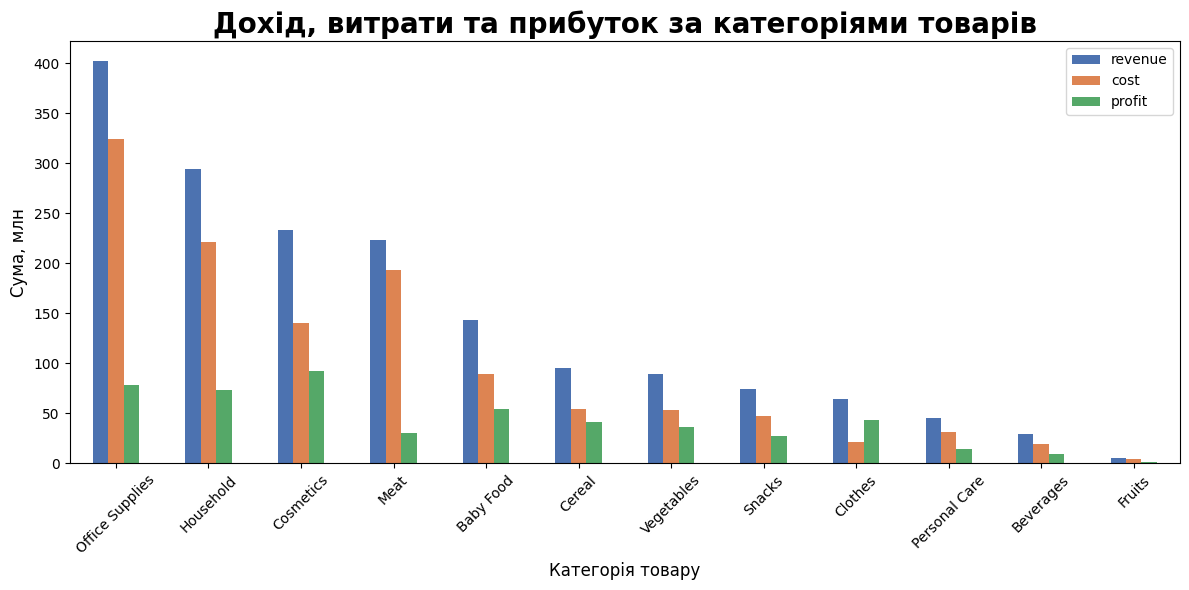

In [147]:
df_plot = (pivot_table_category_item[["revenue", "cost", "profit"]] / 1_000_000).reset_index()

df_plot.plot(kind = "bar", x = "item_type", y = ["revenue", "cost", "profit"], color = sns.color_palette("deep", 3), figsize = (12, 6))

plt.title("Дохід, витрати та прибуток за категоріями товарів", size = 20, fontweight = "bold")
plt.xlabel("Категорія товару", size = 12)
plt.ylabel("Сума, млн", size = 12)
plt.xticks(rotation = 45)

plt.tight_layout()
plt.show()

Можемо бачити, що такі категорії як: `Office Supplies`, `Household` та `Cosmetics` є лідерами у прибутку за категоріями. А категорії: `Fruits`, `Beverages` та `Personal Care` є найменш прибутковими категоріями товарів.

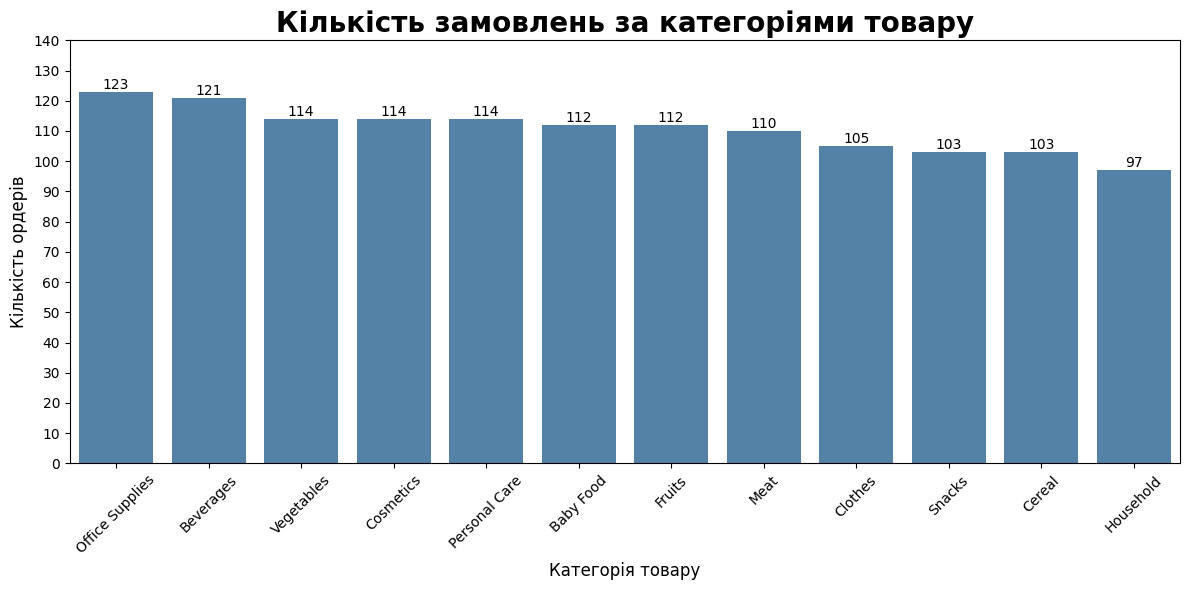

In [148]:
plt.figure(figsize = (12, 6))

bars = sns.barplot(data = pivot_table_category_item.sort_values(by = "order_id", ascending = False), x = "item_type", y = "order_id", color = "steelblue")

bars.bar_label(bars.containers[0], color="black", fontsize=10)

plt.title("Кількість замовлень за категоріями товару", size = 20, fontweight = "bold")
plt.xlabel("Категорія товару", size = 12)
plt.ylabel("Кількість ордерів", size = 12)
plt.xticks(rotation = 45)
plt.yticks(range(0, pivot_table_category_item['order_id'].max() + 20, 10))

plt.tight_layout()
plt.show()

Можемо бачити що найбільшу кількість замовлень мають категорії: `Office Supplies`, `Beverages`, `Vegetables`. А категорії: `Household`, `Cereal` та `Snacks` маюь найеншу кількість замовлень. Вже можна помітити, що `Office Supplies` це категорія яка знаходиться в лідерах для кількості та сумі доходів, також є категорія `Beverages` яка має низький дохід, але велику кількість замовлень. Ще є категорія, `Household` яка має високий дохід, але низьку кількість замовлень.

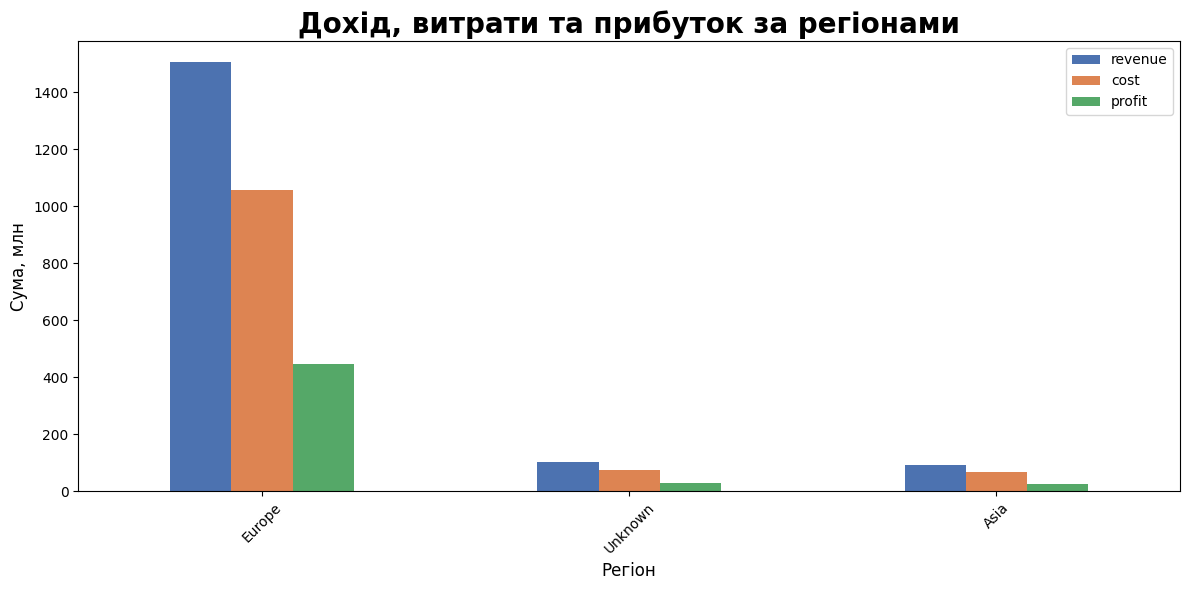

In [149]:
df_plot = (pivot_table_region[["revenue", "cost", "profit"]] / 1_000_000).reset_index()

df_plot.plot(kind = "bar", x = "region", y = ["revenue", "cost", "profit"], color = sns.color_palette("deep", 3), figsize = (12, 6))

plt.title("Дохід, витрати та прибуток за регіонами", size = 20, fontweight = "bold")
plt.xlabel("Регіон", size = 12)
plt.ylabel("Сума, млн", size = 12)
plt.xticks(rotation = 45)

plt.tight_layout()
plt.show()

Можемо бачити, що лідером по регіонам є `Europe`, яка складає 90% від загальних доходів. Найменш прибутковою є регіон `Asia` та також, тут є регіон країн для яких він не був вказаним (`Unknown`).

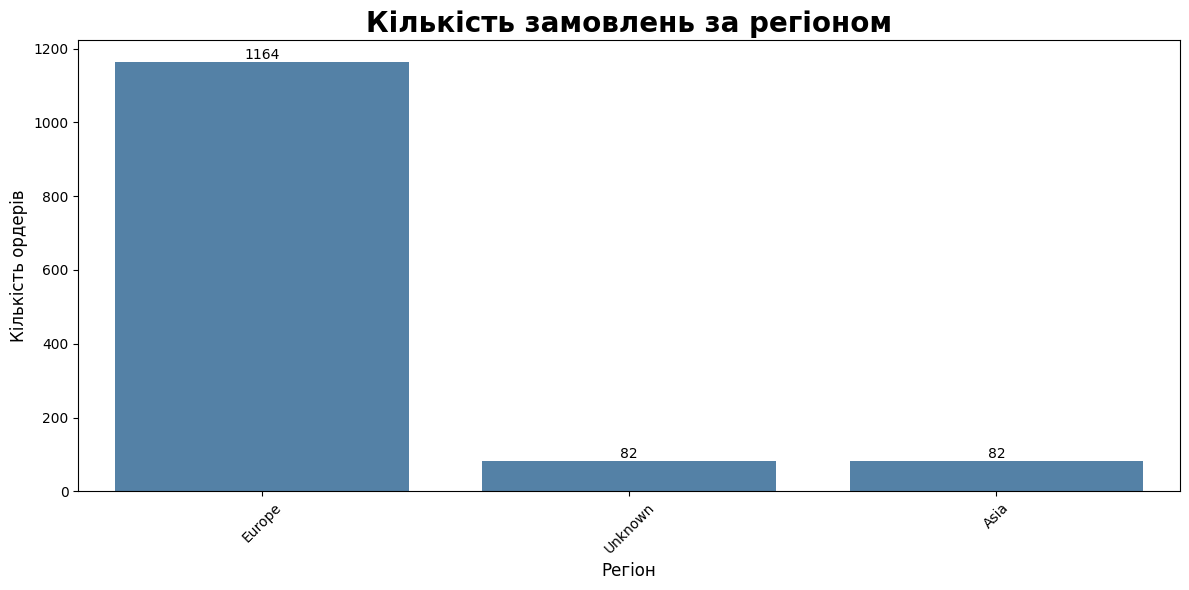

In [150]:
plt.figure(figsize = (12, 6))

bars = sns.barplot(data = pivot_table_region.sort_values(by = "order_id", ascending = False), x = "region", y = "order_id", color = "steelblue")
bars.bar_label(bars.containers[0], color="black", fontsize=10)

plt.title("Кількість замовлень за регіоном", size = 20, fontweight = "bold")
plt.xlabel("Регіон", size = 12)
plt.ylabel("Кількість ордерів", size = 12)
plt.xticks(rotation = 45)

plt.tight_layout()
plt.show()

Бачимо, що для кількості замовлень, результат такий самий як і для доходів. Лідером є `Europe` та регіон з найменшою кількістю замолень - `Asia`.

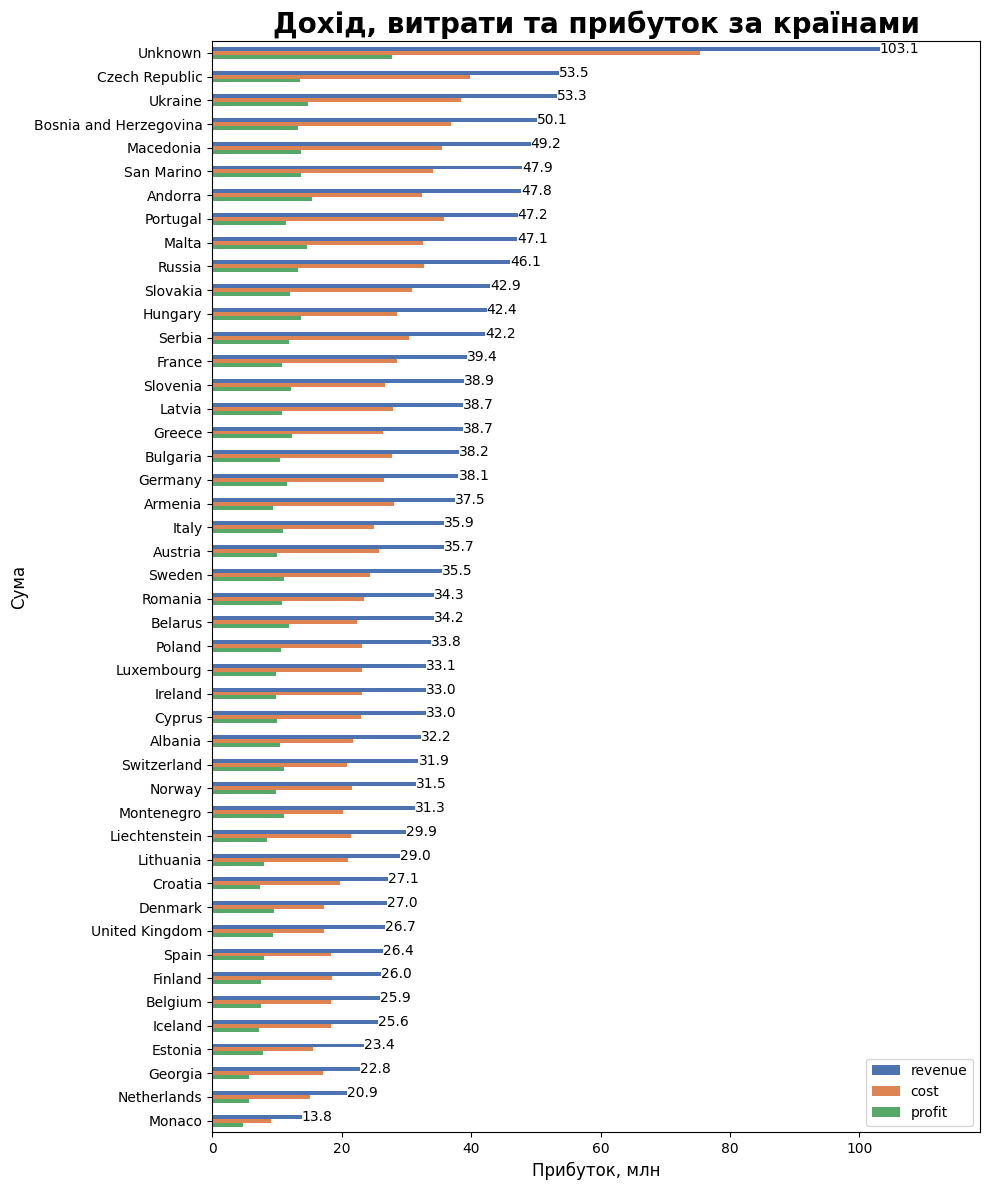

In [151]:
df_plot = (pivot_table_country[["revenue", "cost", "profit"]] / 1_000_000).reset_index()

bars = df_plot.plot(kind = "barh", x = "country", y = ["revenue", "cost", "profit"], color = sns.color_palette("deep", 3), figsize = (10, 12))

plt.gca().invert_yaxis()

bars.bar_label(bars.containers[0], color="black", fmt="%.1f", fontsize=10)

plt.title("Дохід, витрати та прибуток за країнами", size = 20, fontweight = "bold")
plt.xlabel("Прибуток, млн", size = 12)
plt.ylabel("Сума", size = 12)
plt.xlim(0, df_plot["revenue"].max() * 1.15)

plt.tight_layout()
plt.show()

Топ 3 країни за доходом: `Unknown`, `Czech Republic` та `Ukraine`. Розрив між `Unknown` та іншими країнами, більше чим в 2 рази, через те що в базі даних були невідомі країни, і тому всі їх доходи, витрати та профіт були підсумовані в одну категорію. Найменш прибутковими є `Georgia`, `Netherlands`, `Monaco`.

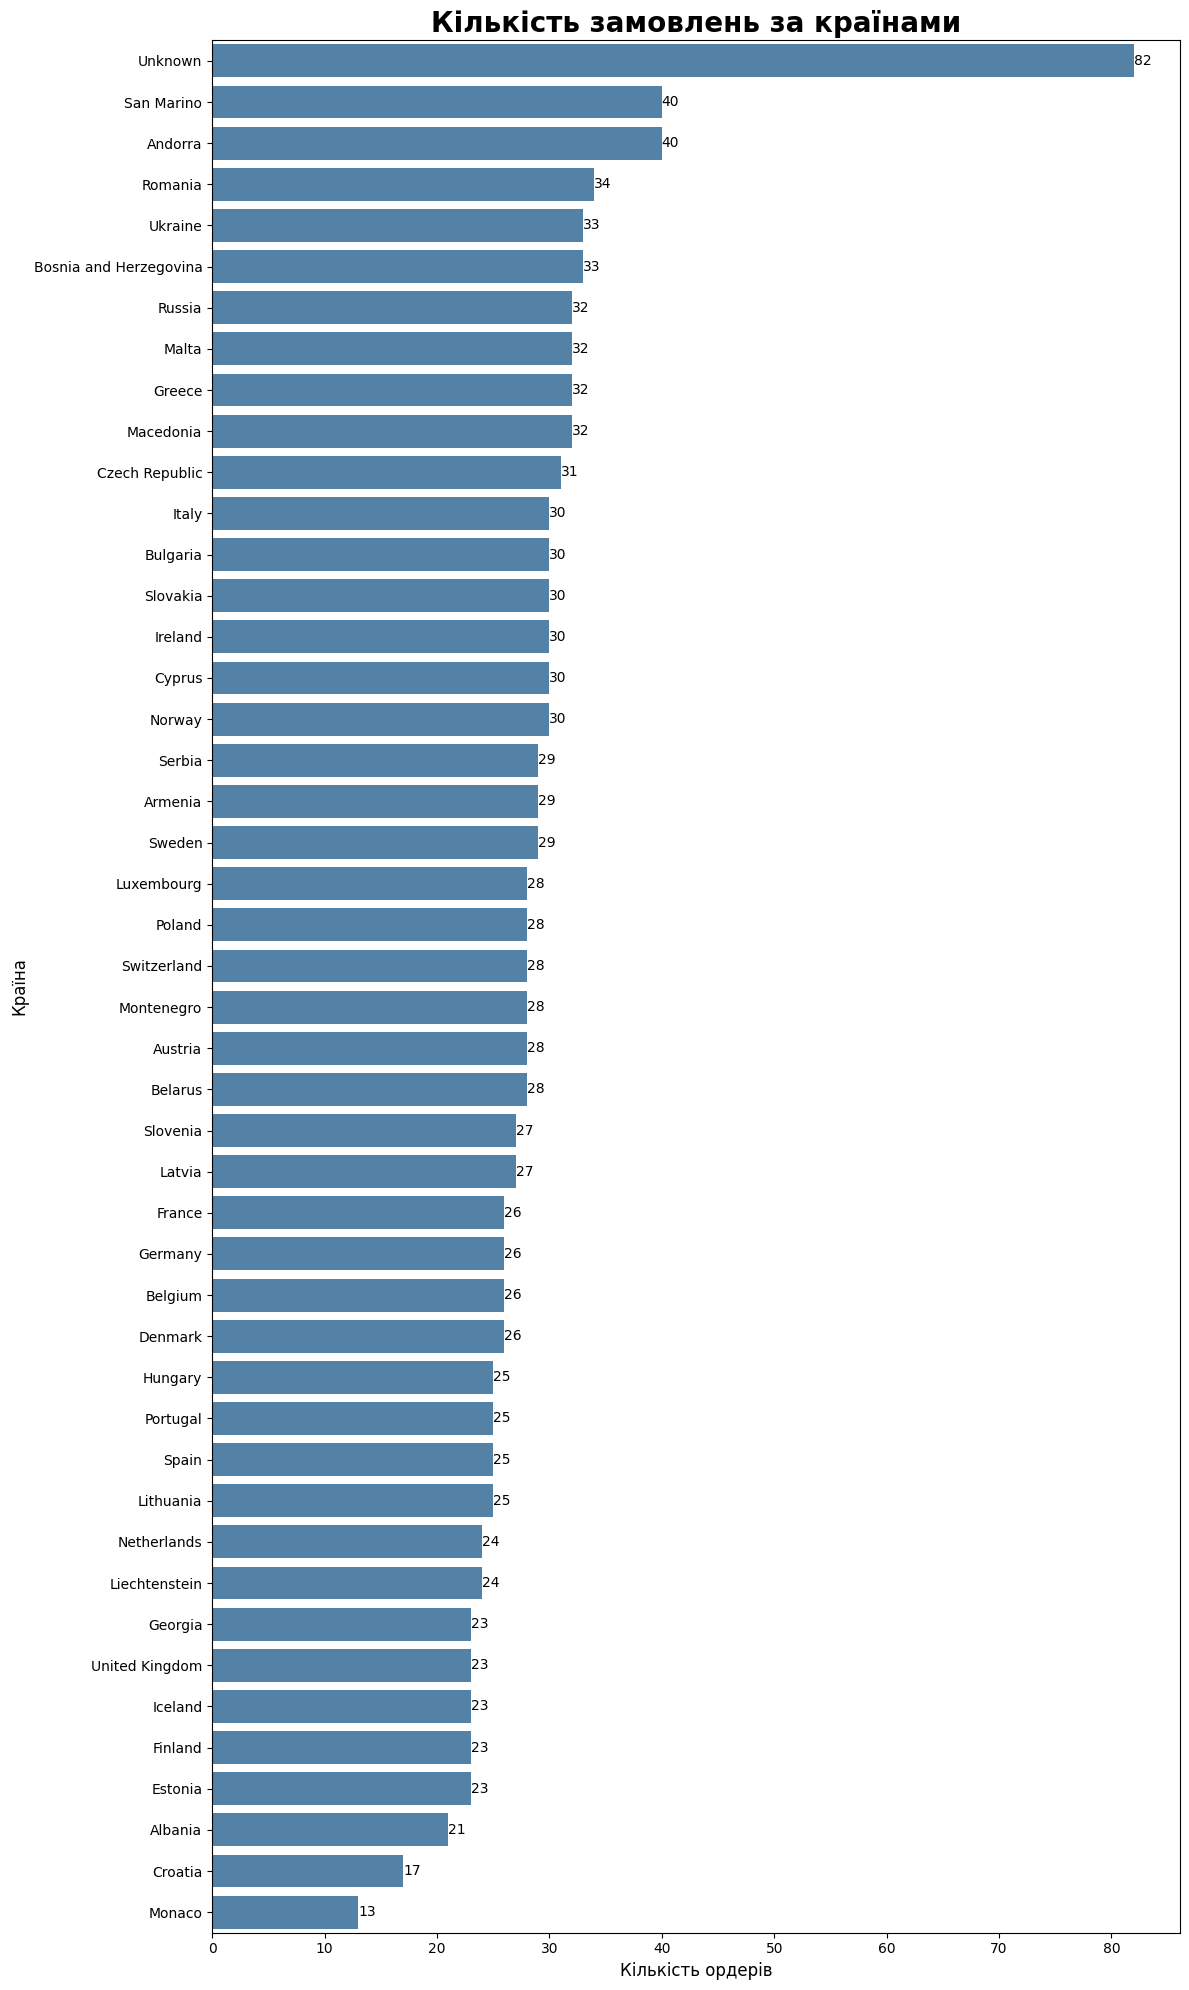

In [152]:
plt.figure(figsize = (12, 20))

bars = sns.barplot(data = pivot_table_country.sort_values(by = "order_id", ascending = False), x = "order_id", y = "country", color = "steelblue")

bars.bar_label(bars.containers[0], color="black", fontsize=10)

plt.title("Кількість замовлень за країнами", size = 20, fontweight = "bold")
plt.xlabel("Кількість ордерів", size = 12)
plt.ylabel("Країна", size = 12)

plt.tight_layout()
plt.show()

Топ 3 країни за кількістю замовлень: `Unknown`, `San Marino` та `Andorra`. Тут ситуація з відривом `Unknown` від всіх інших, ідентична до доходу. Найменшу кількість замовлень мають такі країни: `Monaco`, `Croatia`, `Albania`.

Якщо не враховувати список країн які збережені під назвою - `Unknown` то можемо помітити, що `Monaco` та країна яка одночасно маю низьку кількість замовлень та приносить низький дохід.

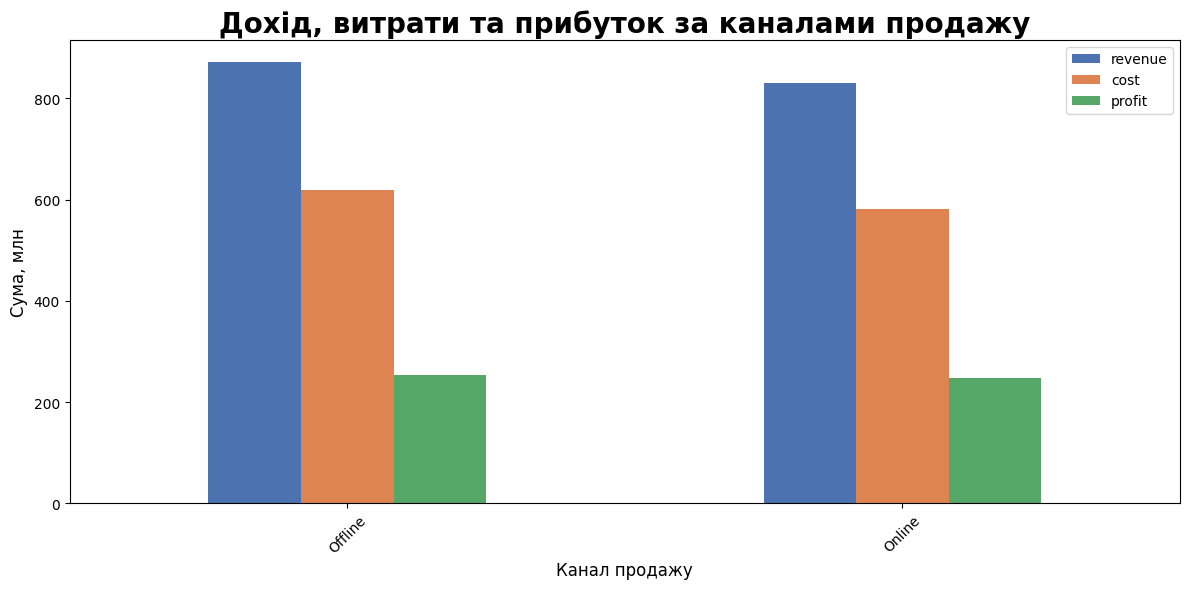

In [153]:
df_plot = (pivot_table_sales_channel[["revenue", "cost", "profit"]] / 1_000_000).reset_index()

df_plot.plot(kind = "bar", x = "sales_channel", y = ["revenue", "cost", "profit"], color = sns.color_palette("deep", 3), figsize = (12, 6))

plt.title("Дохід, витрати та прибуток за каналами продажу", size = 20, fontweight = "bold")
plt.xlabel("Канал продажу", size = 12)
plt.ylabel("Сума, млн", size = 12)
plt.xticks(rotation = 45)

plt.tight_layout()
plt.show()

Можемо бачити, що обидва канали містять майже однакові показники, що свідчить про те що вони обидва користуються популярністю і приносять рівний дохід.

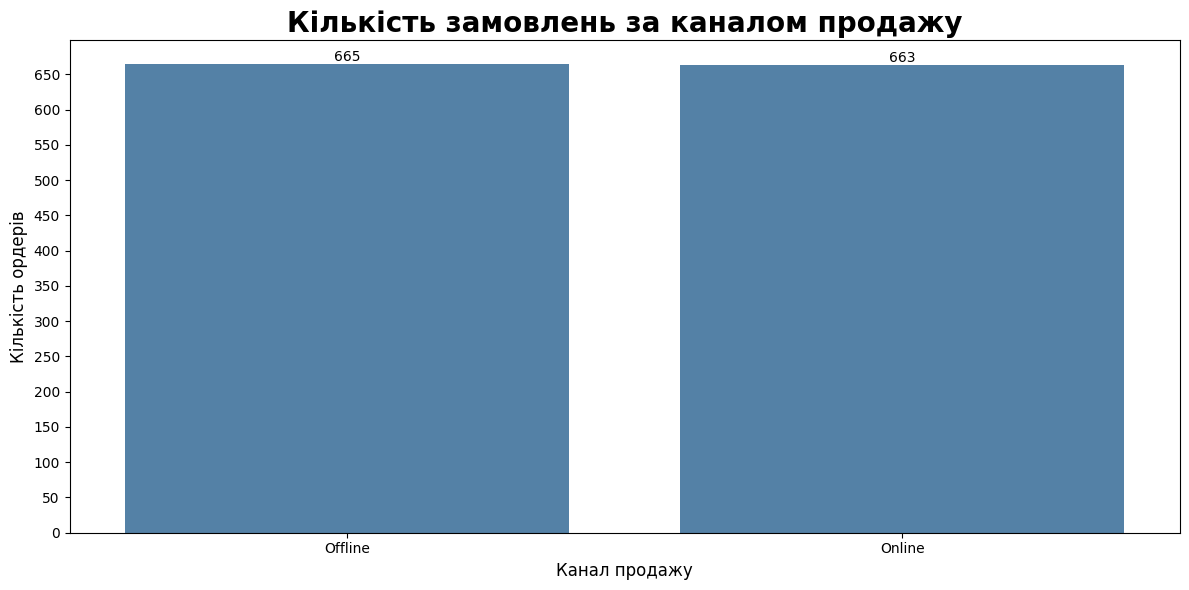

In [154]:
plt.figure(figsize = (12, 6))

bars = sns.barplot(data = pivot_table_sales_channel.sort_values(by = "order_id", ascending = False), x = "sales_channel", y = "order_id", color = "steelblue")

bars.bar_label(bars.containers[0], color="black", fontsize=10)

plt.title("Кількість замовлень за каналом продажу", size = 20, fontweight = "bold")
plt.xlabel("Канал продажу", size = 12)
plt.ylabel("Кількість ордерів", size = 12)
plt.yticks(range(0, pivot_table_sales_channel['order_id'].max() + 20, 50))

plt.tight_layout()
plt.show()

Кількість замовлень мід ними також майже однакова, тому необхідно родовжувати розвивати їх обох.

### 3.4) Проаналізувати інтервал часу між замовленням та його відвантаженням та зробити відповідні візуалізації в розрізі:
* **категорій товарів**;
* **країн**;
* **регіонів**.

In [155]:
df_merged_update.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1328 entries, 0 to 1327
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        1328 non-null   int64         
 1   order_date      1328 non-null   datetime64[ns]
 2   ship_date       1328 non-null   datetime64[ns]
 3   order_priority  1328 non-null   object        
 4   country_code    1328 non-null   object        
 5   product_id      1328 non-null   int64         
 6   sales_channel   1328 non-null   object        
 7   units_sold      1328 non-null   int64         
 8   unit_price      1328 non-null   float64       
 9   unit_cost       1328 non-null   float64       
 10  country         1328 non-null   object        
 11  region          1328 non-null   object        
 12  sub_region      1328 non-null   object        
 13  item_type       1328 non-null   object        
 14  revenue         1328 non-null   float64       
 15  cost

In [156]:
df_merged_update["time_delivery"] = (df_merged_update["ship_date"] - df_merged_update["order_date"]).dt.days

In [157]:
df_merged_update.head()
df_merged_update.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1328 entries, 0 to 1327
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        1328 non-null   int64         
 1   order_date      1328 non-null   datetime64[ns]
 2   ship_date       1328 non-null   datetime64[ns]
 3   order_priority  1328 non-null   object        
 4   country_code    1328 non-null   object        
 5   product_id      1328 non-null   int64         
 6   sales_channel   1328 non-null   object        
 7   units_sold      1328 non-null   int64         
 8   unit_price      1328 non-null   float64       
 9   unit_cost       1328 non-null   float64       
 10  country         1328 non-null   object        
 11  region          1328 non-null   object        
 12  sub_region      1328 non-null   object        
 13  item_type       1328 non-null   object        
 14  revenue         1328 non-null   float64       
 15  cost

In [158]:
pivot_table_category_item_by_order_ship_date = df_merged_update.pivot_table(values = "time_delivery", index = "item_type", aggfunc = "mean").astype(int)
print(pivot_table_category_item_by_order_ship_date)

                 time_delivery
item_type                     
Baby Food                   26
Beverages                   24
Cereal                      27
Clothes                     23
Cosmetics                   25
Fruits                      24
Household                   23
Meat                        25
Office Supplies             26
Personal Care               20
Snacks                      25
Vegetables                  23


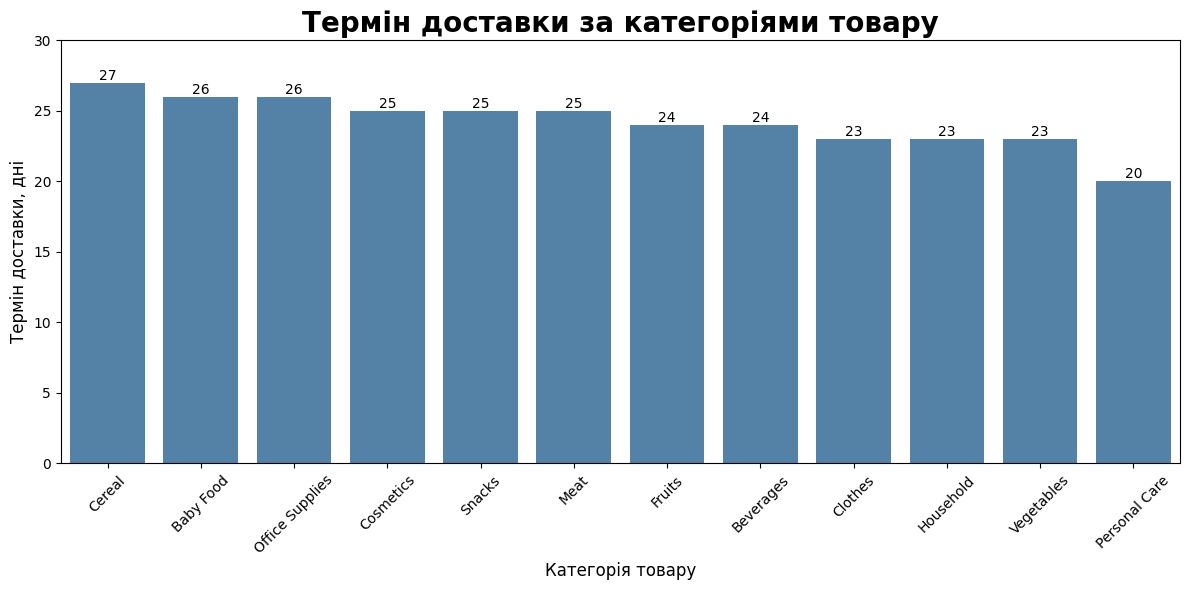

In [159]:
plt.figure(figsize = (12, 6))

bars = sns.barplot(data = pivot_table_category_item_by_order_ship_date.sort_values(by = "time_delivery", ascending = False), x = "item_type", y = "time_delivery", color = "steelblue")

bars.bar_label(bars.containers[0], color="black", fontsize=10)

plt.title("Термін доставки за категоріями товару", size = 20, fontweight = "bold")
plt.xlabel("Категорія товару", size = 12)
plt.ylabel("Термін доставки, дні", size = 12)
plt.xticks(rotation = 45)
plt.yticks(range(0, pivot_table_category_item_by_order_ship_date["time_delivery"].max() + 5, 5))

plt.tight_layout()
plt.show()

Бачимо, що для середнього показника терміну доставки, лідерами, з найменшою кількістю днів є: `Personal Care`, `Vegetables`, `Household`, вони тримаються в діапазоні від 20 до 25 днів в середньому. Найдовші терміни доставки мають такі категорії, як: `Cerael`, `Baby Food`, `Office Supplies`. Їх діапазон термінів доставки, в середньому, від 25 до 30 днів.

In [160]:
pivot_table_country_by_order_ship_date = df_merged_update.pivot_table(values = "time_delivery", index = "country", aggfunc = "mean").astype(int)
print(pivot_table_country_by_order_ship_date)

                        time_delivery
country                              
Albania                            26
Andorra                            26
Armenia                            26
Austria                            28
Belarus                            25
Belgium                            26
Bosnia and Herzegovina             26
Bulgaria                           26
Croatia                            18
Cyprus                             23
Czech Republic                     25
Denmark                            19
Estonia                            20
Finland                            26
France                             26
Georgia                            29
Germany                            23
Greece                             23
Hungary                            32
Iceland                            23
Ireland                            23
Italy                              25
Latvia                             20
Liechtenstein                      22
Lithuania   

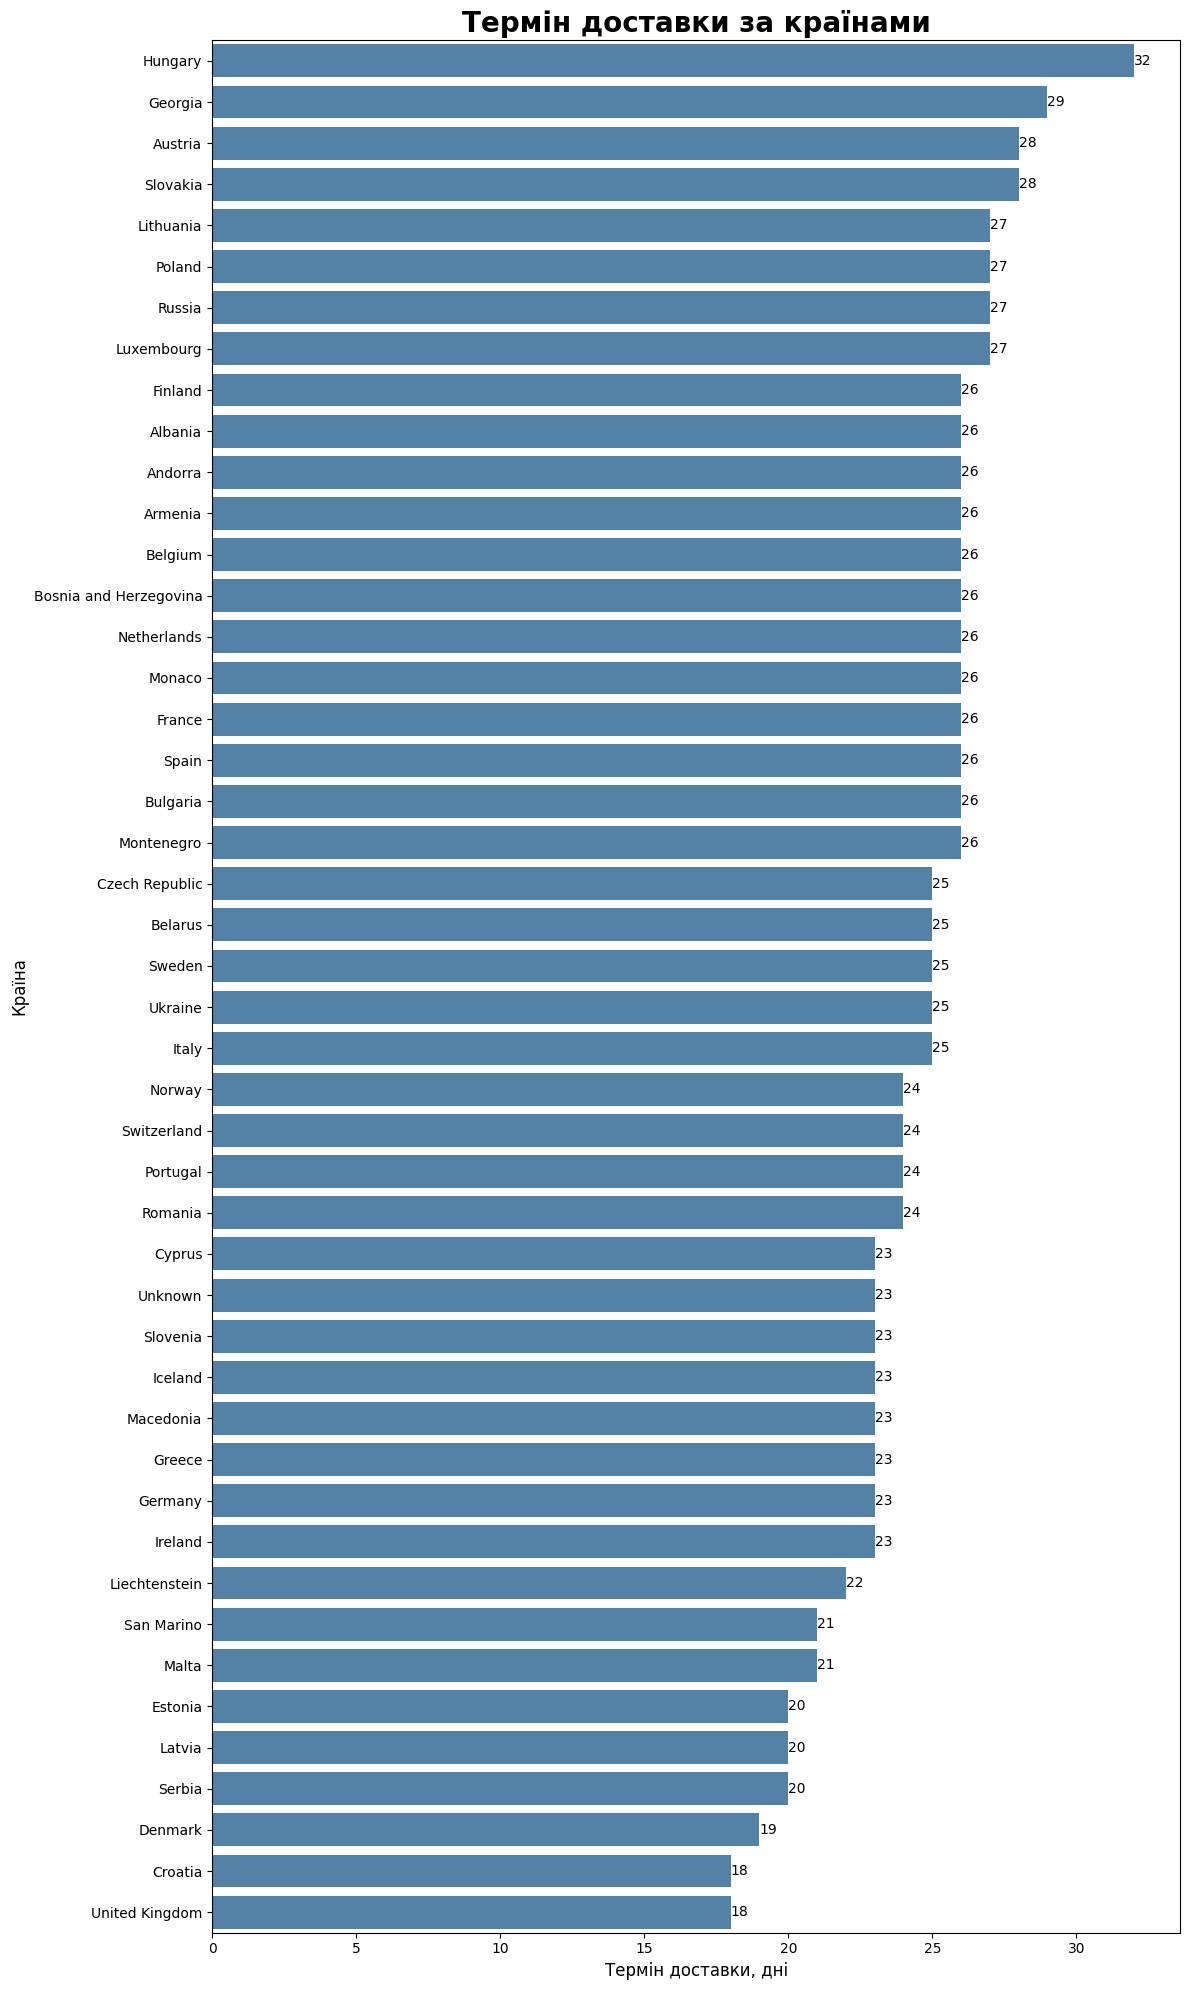

In [161]:
plt.figure(figsize = (12, 20))

bars = sns.barplot(data = pivot_table_country_by_order_ship_date.sort_values(by = "time_delivery", ascending = False), x = "time_delivery", y = "country", color = "steelblue")

bars.bar_label(bars.containers[0], color="black", fontsize=10)

plt.title("Термін доставки за країнами", size = 20, fontweight = "bold")
plt.xlabel("Термін доставки, дні", size = 12)
plt.ylabel("Країна", size = 12)

plt.tight_layout()
plt.show()

Бачимо, що для середнього показника терміну доставки, лідерами, з найменшою кількістю днів є: `United Kingdom`, `Croatia`, `Denmark`, вони тримаються в діапазоні від 18 до 19 днів в середньому. Найдовші терміни доставки мають такі Країни, як: `Hungary`, `Georgia`, `Austria`. Їх діапазон термінів доставки, в середньому, від 28 до 32 днів.

In [162]:
pivot_table_region_order_ship_date = df_merged_update.pivot_table(values = "time_delivery", index = "region", aggfunc = "mean").astype(int)
print(pivot_table_region_order_ship_date)

         time_delivery
region                
Asia                26
Europe              24
Unknown             23


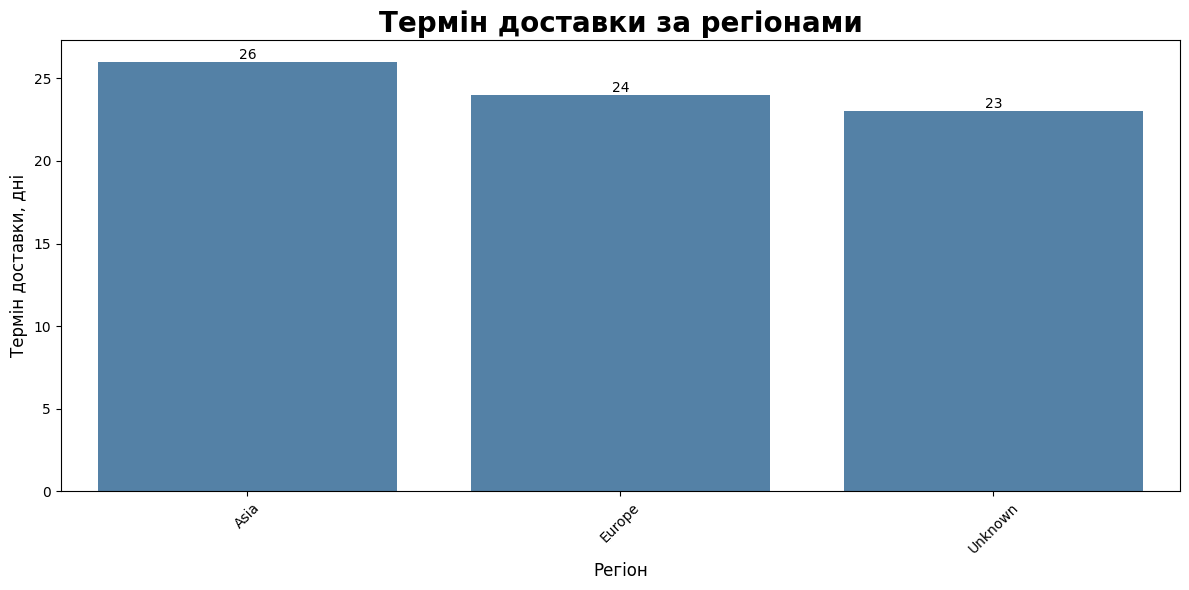

In [163]:
plt.figure(figsize = (12, 6))

bars = sns.barplot(data = pivot_table_region_order_ship_date.sort_values(by = "time_delivery", ascending = False), x = "region", y = "time_delivery", color = "steelblue")

plt.title("Термін доставки за регіонами", size = 20, fontweight = "bold")
bars.bar_label(bars.containers[0], color="black", fontsize=10)

plt.xlabel("Регіон", size = 12)
plt.ylabel("Термін доставки, дні", size = 12)
plt.xticks(rotation = 45)

plt.tight_layout()
plt.show()

Бачимо, що для середнього показника терміну доставки, лідером, з найменшою кількістю днів є: `Europe`, з середнім показником доставки в 24 дня, але це якщо не рахувати, невідомі `регіони` тому що в них середній термін доставки - 23 дня. Найдовший терміни доставки має регіон `Asia`, а саме 26 днів в середньому.

### 3.5) Проаналізувати, чи залежить прибуток від часу, необхідного на відвантаження товару. Зробити потрібні для цього агрегування та візуалізації.

In [164]:
print(df_merged_update[["time_delivery", "profit"]].corr())

               time_delivery    profit
time_delivery       1.000000  0.060299
profit              0.060299  1.000000


Після числового аналізу ми можемо бачити що кореляція наближена до 0, тобто прямою та позитивної залежності майже немає між прибутком та часом доставки. Хоча тенденція наближенна до нуля але має мінімальний позитивний характер, тобто час доставки не є основним чииником яким впливає на профіт.

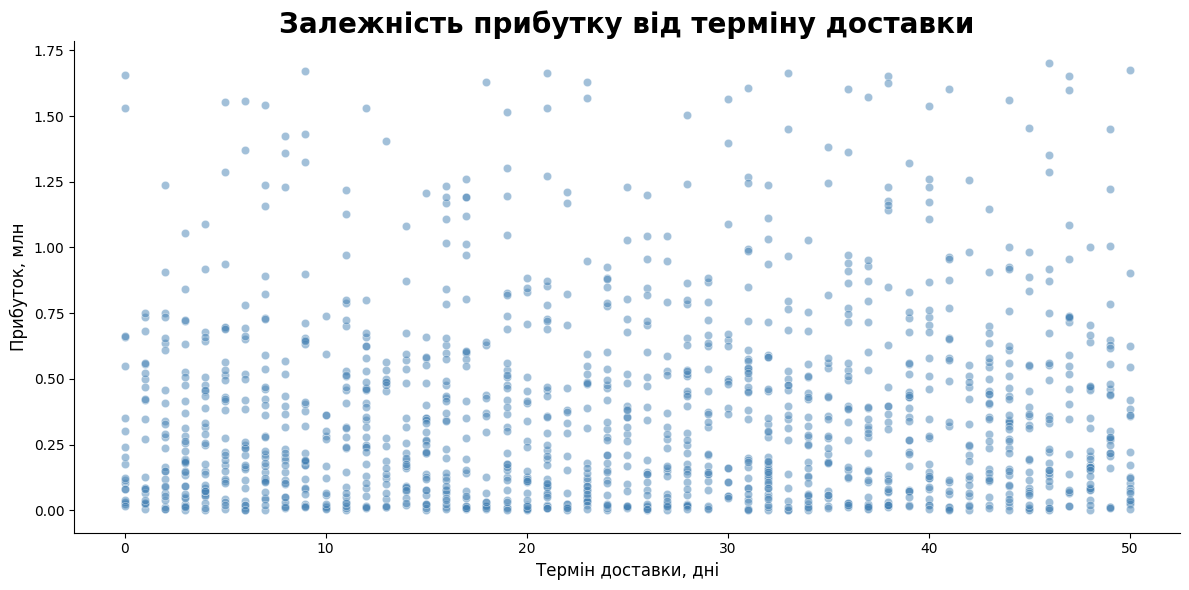

In [165]:
sns.relplot(data = df_merged_update.assign(profit = lambda x: x["profit"] / 1_000_000), x = "time_delivery", y = "profit", height = 6, aspect = 2, color = "steelblue", alpha = 0.5)

plt.title("Залежність прибутку від терміну доставки", size = 20, fontweight = "bold")
plt.xlabel("Термін доставки, дні", size = 12)
plt.ylabel("Прибуток, млн", size = 12)

plt.tight_layout()
plt.show()

Бачимо велику концентрацію та затемнення точок по всьому діапазону термінів доставки але в основному для прибутку в діапазоні від `0` до `0,6` млн. тобто ріст є, але мінімальний, що можемо побачити і за дпомогою цього графіку залежностей так і за допомогою таблички вище. Тобто час на доставку товарів не впливає на прибутковість замовлення.

### 3.6) Проаналізувати за допомогою візуалізації динаміку продажів (у часі) у розрізі категорій товарів, країн, регіонів, визначити основні тенденції.

In [166]:
df_merged_update.head()

,order_id,order_date,ship_date,order_priority,country_code,product_id,sales_channel,units_sold,unit_price,unit_cost,country,region,sub_region,item_type,revenue,cost,profit,time_delivery
0,100640618,2014-10-08,2014-10-18,M,NOR,2103,Online,650,205.70,117.11,Norway,Europe,Northern Europe,Cereal,133705.00,76121.50,57583.50,10
1,100983083,2016-08-11,2016-08-11,C,SRB,2103,Offline,1993,205.70,117.11,Serbia,Europe,Southern Europe,Cereal,409960.10,233400.23,176559.87,0
2,101025998,2014-07-18,2014-08-11,M,Unknown,7940,Online,4693,668.27,502.54,Unknown,Unknown,Unknown,Household,3136191.11,2358420.22,777770.89,24
3,102230632,2017-05-13,2017-06-13,L,MNE,2455,Online,1171,109.28,35.84,Montenegro,Europe,Southern Europe,Clothes,127966.88,41968.64,85998.24,31
4,103435266,2012-08-11,2012-09-18,H,SRB,1270,Offline,7648,47.45,31.79,Serbia,Europe,Southern Europe,Beverages,362897.60,243129.92,119767.68,38


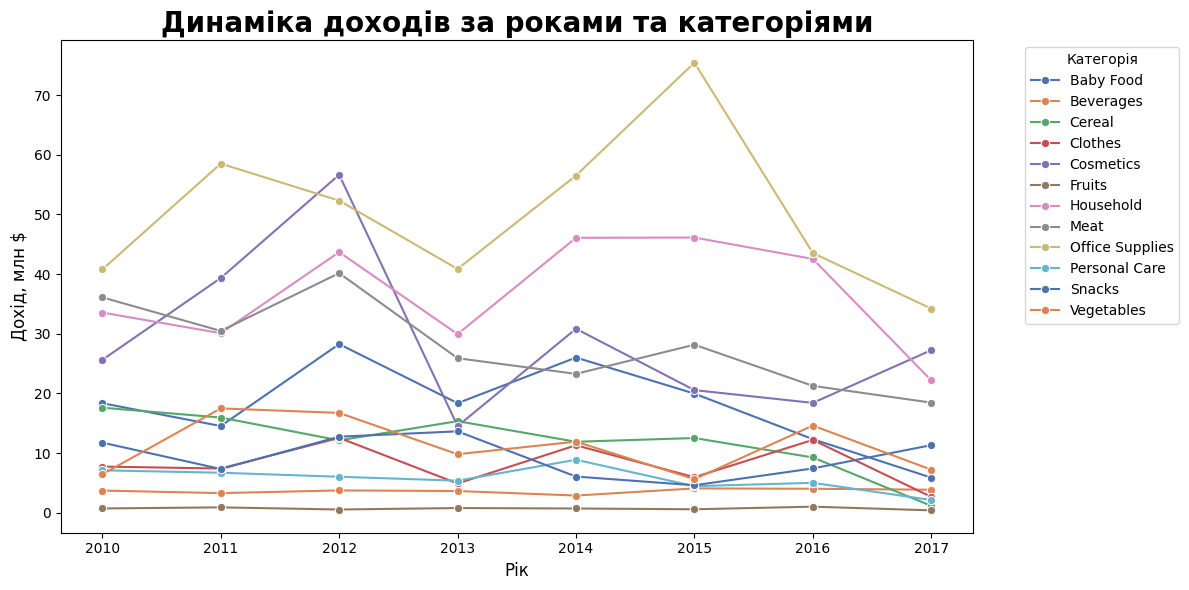

In [167]:
yearly_category = (
    df_merged_update.assign(year = df_merged_update["order_date"].dt.year)
    .groupby(["year", "item_type"])["revenue"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data = yearly_category.assign(revenue_mln = lambda x: x["revenue"] / 1_000_000),
    x = "year",
    y = "revenue_mln",
    hue = "item_type",
    marker = "o",
    palette = "deep",
)

plt.title("Динаміка доходів за роками та категоріями", size = 20, fontweight="bold")
plt.xlabel("Рік", size = 12)
plt.ylabel("Дохід, млн $", size = 12)


plt.legend(bbox_to_anchor = (1.05, 1), loc = "upper left", title = "Категорія")
plt.tight_layout()
plt.show()

Можемо бачити що деякі категорії товарів не змінються або майже не змінюється навіть по всьому діапазону років, а саме: `Cerael`, `Baby Food`, `Clothes`, `Personal Care`, `Vegetables`, `Beverages`, `Fruits`. Вони знаходяться в діапазоні доходів від 0 до 20 млн. Ще є категорія `Snacks`, вона також починала з цього діапазону доходів (від 0 до 20 млн) мала активний ріст з 2010 до 2012 року, але потім повернулась в перший діапазон доходів, та в 2017 отримала доходів менше у 2 рази ніж у 2010 (10 млн). Всі інші категорії, а саме: `Cosmetics`, `Household`, `Meat`, `Office Supplies` були в діапазоні доходів від 25 до 40 млн у 2010 а в 2017 знаходяться в діапазоні від 20 до 35 млн, що свідчить про те що йде поступове зниження доходів.

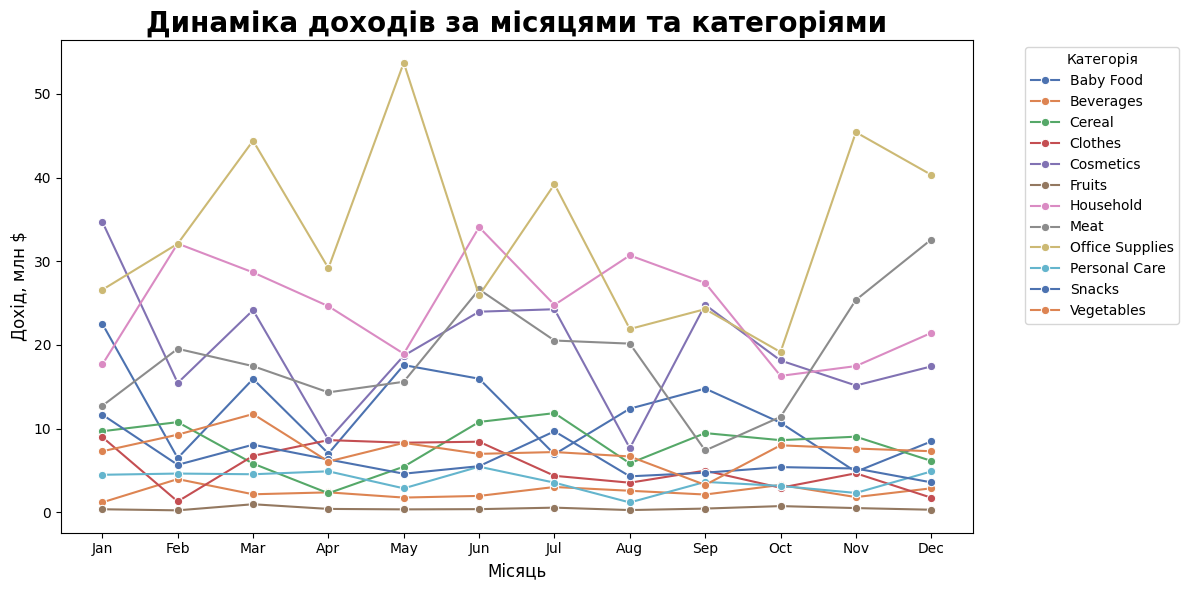

In [168]:
monthly_category = (
    df_merged_update.assign(month=df_merged_update["order_date"].dt.month)
    .groupby(["month", "item_type"])["revenue"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data = monthly_category.assign(
        revenue_mln = lambda x: x["revenue"] / 1_000_000
    ),
    x = "month",
    y = "revenue_mln",
    hue = "item_type",
    marker = "o",
    palette = "deep",
)

plt.title(
    "Динаміка доходів за місяцями та категоріями", size = 20, fontweight = "bold"
)
plt.xlabel("Місяць", size = 12)
plt.ylabel("Дохід, млн $", size = 12)

months_labels = [
    "Jan",
    "Feb",
    "Mar",
    "Apr",
    "May",
    "Jun",
    "Jul",
    "Aug",
    "Sep",
    "Oct",
    "Nov",
    "Dec",
]
plt.xticks(ticks = range(1, 13), labels=months_labels)

plt.legend(bbox_to_anchor = (1.05, 1), loc = "upper left", title = "Категорія")
plt.tight_layout()
plt.show()

Можемо бачити що деякі категорії товарів не змінються або майже не змінюється навіть по всьому діапазону місяців, а саме: `Cerael`, `Baby Food`, `Clothes`, `Personal Care`, `Vegetables`, `Beverages`, `Fruits`. Вони знаходяться в діапазоні доходів від 0 до 10 млн. Загалом ситуація схожа на ситуацію з роками, але тут можна помітити ріст доходів з листопада по травень майже у всіх категоріях, але також можна помітити дивний викид, категорії `Office Supplies` в травні.

In [169]:
top_5_countries = df_merged_update.groupby("country")["revenue"].sum().nlargest(5).index

df_top5_countries = df_merged_update[df_merged_update["country"].isin(top_5_countries)]

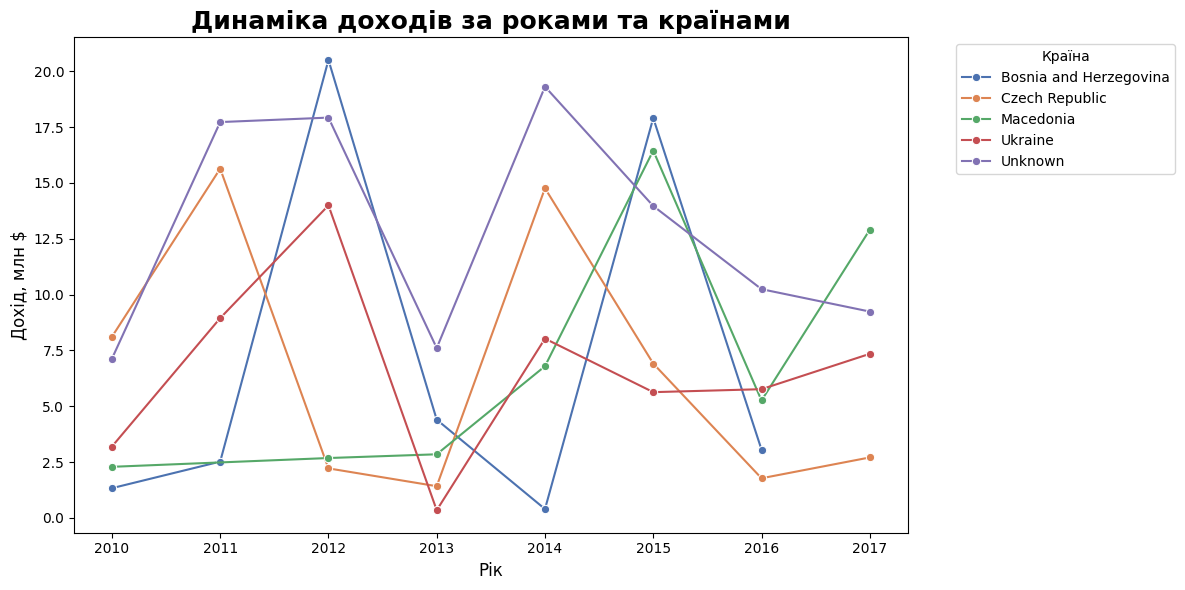

In [170]:
yearly_country = (
    df_top5_countries.assign(year = df_top5_countries["order_date"].dt.year)
    .groupby(["year", "country"])["revenue"]
    .sum()
    .reset_index()
)

plt.figure(figsize = (12, 6))

sns.lineplot(
    data=yearly_country.assign(revenue_mln=lambda x: x["revenue"] / 1_000_000),
    x = "year",
    y = "revenue_mln",
    hue = "country",
    marker = "o",
    palette = "deep",
)

plt.title("Динаміка доходів за роками та країнами", size = 18, fontweight = "bold")
plt.xlabel("Рік", size = 12)
plt.ylabel("Дохід, млн $", size = 12)

plt.legend(bbox_to_anchor = (1.05, 1), loc = "upper left", title = "Країна")
plt.tight_layout()
plt.show()

По країнам з найбільшим доходом, бачимо однакову динаміку зміни руху доходів, тобто для даних країн, `з 2010 по 2011 рік` вийшов зростаючим, `з 2011 по 2012 рік` в основному продовжилась зростаюча тенденція крім (Czech Republic), а ось `з 2012 по 2013 рік` виявились спадаючим по доходу, або майже незміним (Macedonia), `з 2013 по 2014` зростаючий дохід у всіх крім Bosnia and Herzegovina, ще в діапазоні `з 2014 по 2015` - Macedonia та Bosnia and Herzegovina отримали прирість доходів. Тобто ситуація містить щорічне збільшення та зниження доходів на наступний рік. `З 2010 по 2017` всі країни або мають більший дохід або майже такий самий, що свідчить про певний ріст доходу.

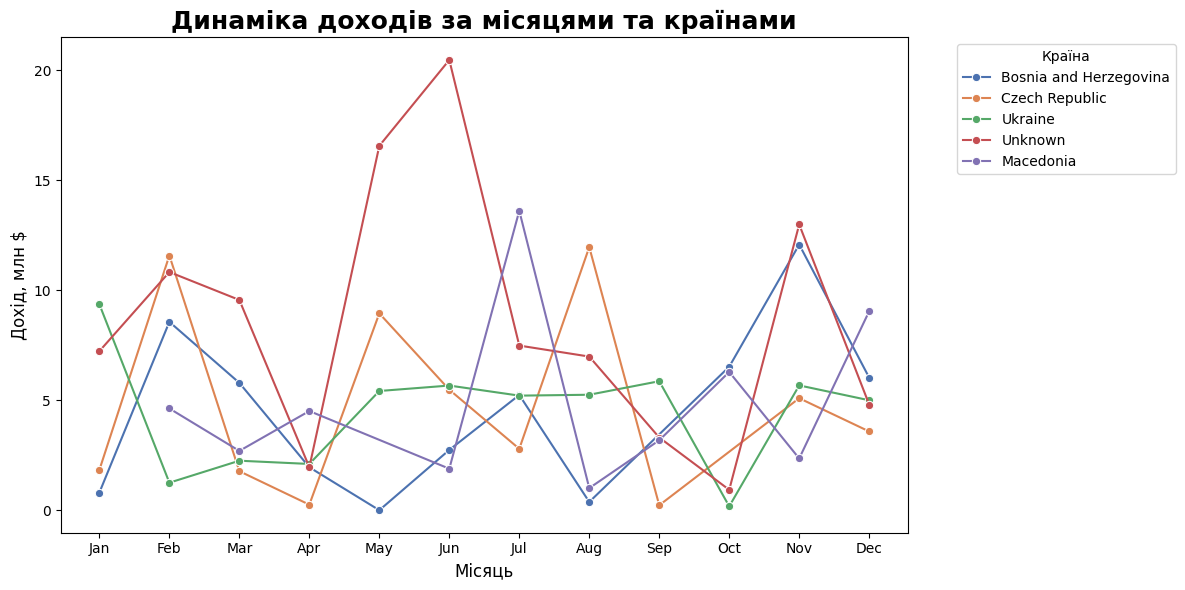

In [171]:
monthly_country = (
    df_top5_countries.assign(month = df_top5_countries["order_date"].dt.month)
    .groupby(["month", "country"])["revenue"]
    .sum()
    .reset_index()
)

plt.figure(figsize = (12, 6))

sns.lineplot(
    data=monthly_country.assign(revenue_mln = lambda x: x["revenue"] / 1_000_000),
    x = "month",
    y = "revenue_mln",
    hue = "country",
    marker = "o",
    palette = "deep",
)

plt.title("Динаміка доходів за місяцями та країнами", size = 18, fontweight = "bold")
plt.xlabel("Місяць", size = 12)
plt.ylabel("Дохід, млн $", size = 12)

months_labels = [
    "Jan",
    "Feb",
    "Mar",
    "Apr",
    "May",
    "Jun",
    "Jul",
    "Aug",
    "Sep",
    "Oct",
    "Nov",
    "Dec",
]
plt.xticks(ticks=range(1, 13), labels = months_labels)

plt.legend(bbox_to_anchor = (1.05, 1), loc = "upper left", title = "Країна")
plt.tight_layout()
plt.show()

Тут бачимо дуже схожу закономірність як і в роках, поетапне збільшення та зниження доходів. На графіку немає глобальної хвилі, яка б піднімала або опускала продажі у всіх країнах одночасно.

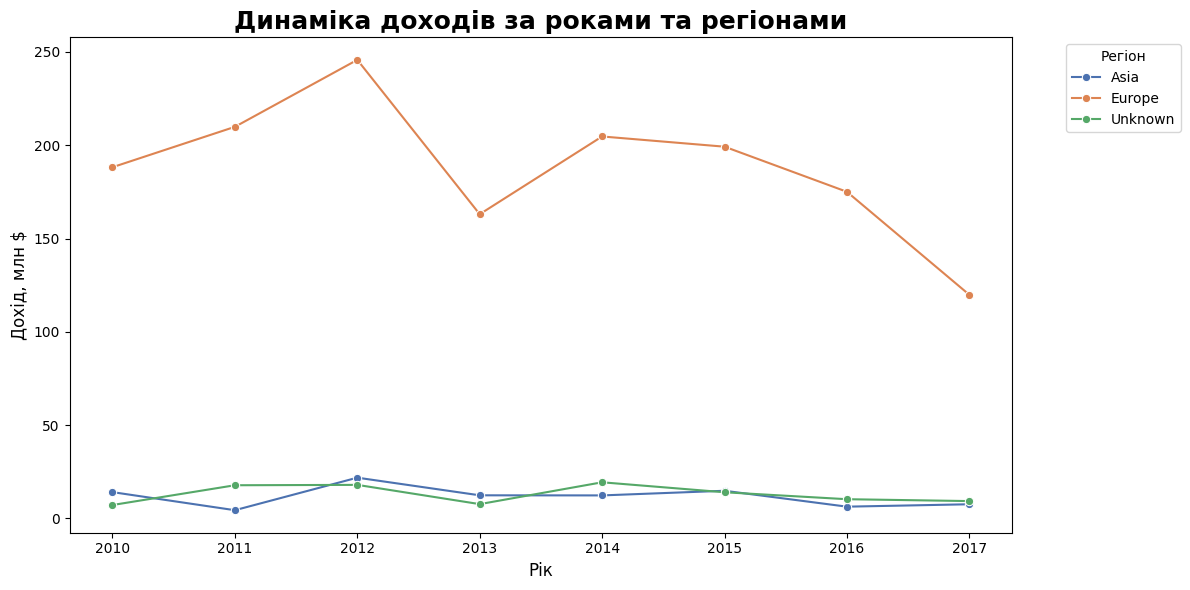

In [172]:
yearly_region = (
    df_merged_update.assign(year = df_merged_update["order_date"].dt.year)
    .groupby(["year", "region"])["revenue"]
    .sum()
    .reset_index()
)

plt.figure(figsize = (12, 6))

sns.lineplot(
    data=yearly_region.assign(revenue_mln=lambda x: x["revenue"] / 1_000_000),
    x = "year",
    y = "revenue_mln",
    hue = "region",
    marker = "o",
    palette = "deep",
)

plt.title("Динаміка доходів за роками та регіонами", size = 18, fontweight = "bold")
plt.xlabel("Рік", size = 12)
plt.ylabel("Дохід, млн $", size = 12)

plt.legend(bbox_to_anchor = (1.05, 1), loc = "upper left", title = "Регіон")
plt.tight_layout()
plt.show()

Бачимо що `Asia` та `Не вказані регіони` знаходяться на одному й тому самому рівні доходів по всьому діапазоні років. А по регіону `Europe` бачимо, що з 2010 по 2012 була позитивна хвиля доходу, а потім почалась поступова негативна хвилю до 2017, з помірним росто в 2014 який не змінює ситуацію яка є спадаючою для доходу. `Europe` 2010 рік - приблизно 180 млн доходу, `Europe` 2017 рік - приблизно 125 млн доходу.

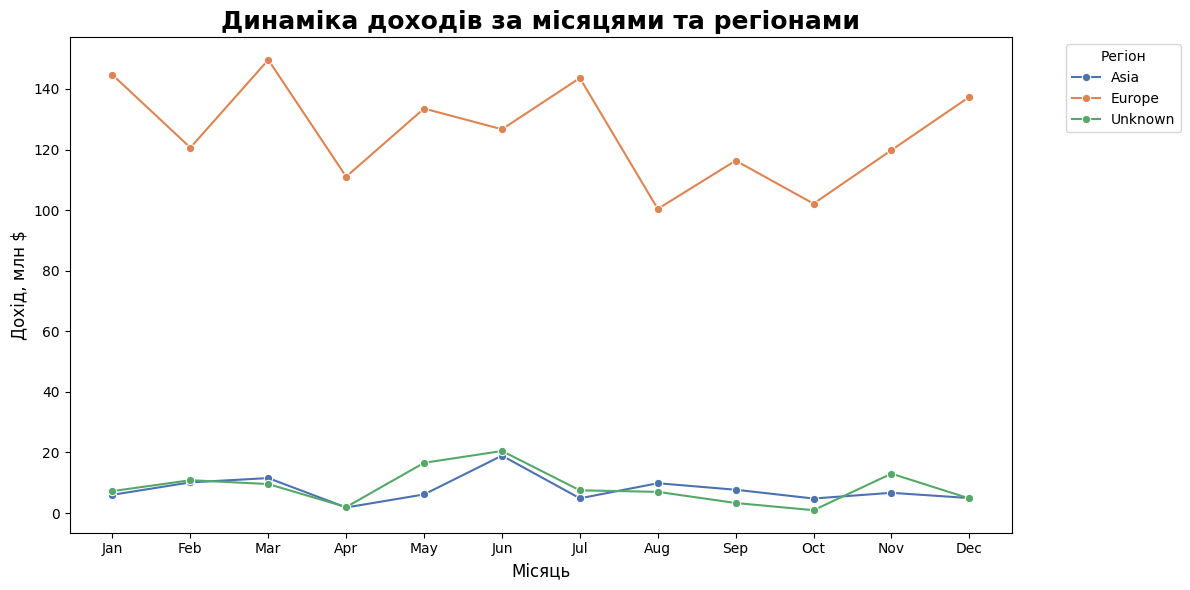

In [173]:
monthly_region = (
    df_merged_update.assign(month = df_merged_update["order_date"].dt.month)
    .groupby(["month", "region"])["revenue"]
    .sum()
    .reset_index()
)

plt.figure(figsize = (12, 6))

sns.lineplot(
    data=monthly_region.assign(revenue_mln = lambda x: x["revenue"] / 1_000_000),
    x = "month",
    y = "revenue_mln",
    hue = "region",
    marker = "o",
    palette = "deep",
)

plt.title("Динаміка доходів за місяцями та регіонами", size = 18, fontweight = "bold")
plt.xlabel("Місяць", size = 12)
plt.ylabel("Дохід, млн $", size = 12)

months_labels = [
    "Jan",
    "Feb",
    "Mar",
    "Apr",
    "May",
    "Jun",
    "Jul",
    "Aug",
    "Sep",
    "Oct",
    "Nov",
    "Dec",
]
plt.xticks(ticks=range(1, 13), labels = months_labels)

plt.legend(bbox_to_anchor = (1.05, 1), loc = "upper left", title = "Регіон")
plt.tight_layout()
plt.show()

Показники `Asia` та `Unknown` протягом усього року знаходяться в діапазоні від 1 до 20 млн. Досягають свого максимума у травні - червні.

`Europe` містить декілька піків доходів, а саме: **Січень** - 145 млн, **Березень** - 150 млн, **Липень** - 140 млн. Маю загалом хвилеподібну динаміку. Та після просідання у **серпні - жовтні** до 100 млн, отримує позитивну хвилю доходів до кінця року, **Грудень** 140 млн

### 3.7) Провести аналіз продажів товарів за днями тижня. Визначити чи можна деякі товари вважати сезонними?

In [174]:
df_merged_update.head()

,order_id,order_date,ship_date,order_priority,country_code,product_id,sales_channel,units_sold,unit_price,unit_cost,country,region,sub_region,item_type,revenue,cost,profit,time_delivery
0,100640618,2014-10-08,2014-10-18,M,NOR,2103,Online,650,205.70,117.11,Norway,Europe,Northern Europe,Cereal,133705.00,76121.50,57583.50,10
1,100983083,2016-08-11,2016-08-11,C,SRB,2103,Offline,1993,205.70,117.11,Serbia,Europe,Southern Europe,Cereal,409960.10,233400.23,176559.87,0
2,101025998,2014-07-18,2014-08-11,M,Unknown,7940,Online,4693,668.27,502.54,Unknown,Unknown,Unknown,Household,3136191.11,2358420.22,777770.89,24
3,102230632,2017-05-13,2017-06-13,L,MNE,2455,Online,1171,109.28,35.84,Montenegro,Europe,Southern Europe,Clothes,127966.88,41968.64,85998.24,31
4,103435266,2012-08-11,2012-09-18,H,SRB,1270,Offline,7648,47.45,31.79,Serbia,Europe,Southern Europe,Beverages,362897.60,243129.92,119767.68,38


In [175]:
df_merged_update.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1328 entries, 0 to 1327
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        1328 non-null   int64         
 1   order_date      1328 non-null   datetime64[ns]
 2   ship_date       1328 non-null   datetime64[ns]
 3   order_priority  1328 non-null   object        
 4   country_code    1328 non-null   object        
 5   product_id      1328 non-null   int64         
 6   sales_channel   1328 non-null   object        
 7   units_sold      1328 non-null   int64         
 8   unit_price      1328 non-null   float64       
 9   unit_cost       1328 non-null   float64       
 10  country         1328 non-null   object        
 11  region          1328 non-null   object        
 12  sub_region      1328 non-null   object        
 13  item_type       1328 non-null   object        
 14  revenue         1328 non-null   float64       
 15  cost

In [176]:
days = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

In [177]:
df_merged_update["day_names"] = pd.Categorical(df_merged_update["order_date"].dt.day_name(), categories=days, ordered=True)

In [178]:
pivot_table_item_by_days = df_merged_update.pivot_table(values = ["revenue", "cost", "profit", "order_id"], index = "day_names", observed=False, aggfunc = {
    "revenue": "sum",
    "cost": "sum",
    "profit": "sum",
    "order_id": "count"
    } )
print(pivot_table_item_by_days)

                   cost  order_id       profit       revenue
day_names                                                   
Monday     1.996781e+08       201  75790330.12  2.754685e+08
Tuesday    1.478865e+08       182  65637400.07  2.135239e+08
Wednesday  1.888919e+08       194  72323843.38  2.612157e+08
Thursday   1.505966e+08       167  64325663.17  2.149222e+08
Friday     1.845725e+08       176  79234529.04  2.638070e+08
Saturday   1.622053e+08       201  71435860.49  2.336411e+08
Sunday     1.668641e+08       207  72686832.73  2.395510e+08


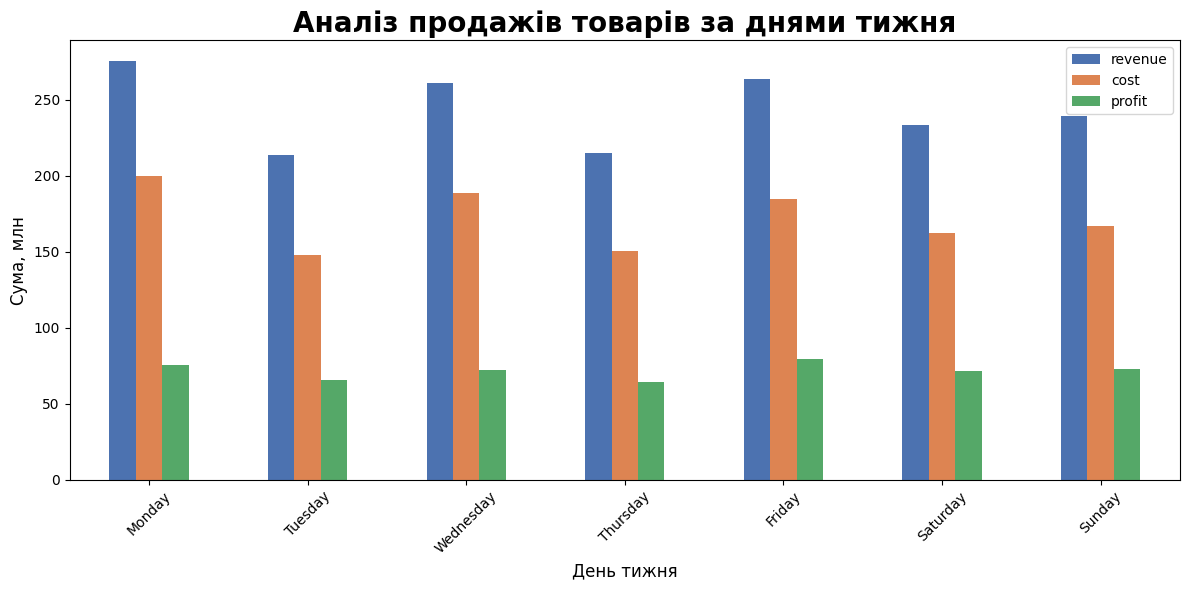

In [179]:
df_plot = (pivot_table_item_by_days[["revenue", "cost", "profit"]] / 1_000_000).reset_index()

df_plot.plot(kind = "bar", x = "day_names", y = ["revenue", "cost", "profit"], color = sns.color_palette("deep", 3), figsize = (12, 6))

plt.title("Аналіз продажів товарів за днями тижня", size = 20, fontweight = "bold")
plt.xlabel("День тижня", size = 12)
plt.ylabel("Сума, млн", size = 12)
plt.xticks(rotation = 45)

plt.tight_layout()
plt.show()

Бачимо що по заробітку, лідерами є `Monday`, `Wednesday` та `Friday`, які знаходяться в діапазоні від 250 до 280 млн, тобто робочі дні, під час яких, виконується основні платіжні операції. Дні з меншими доходами, це: `Tuesday`, `Thursday` та `Saturday`, які знаходяться в діапазоні від 200 до 230 млн.

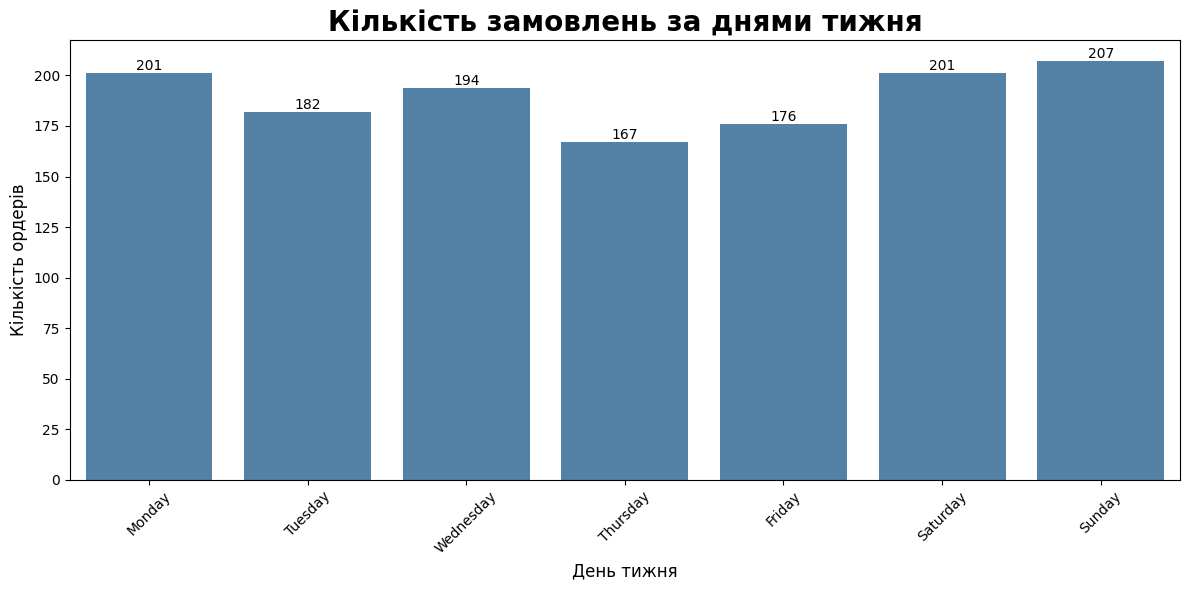

In [180]:
plt.figure(figsize = (12, 6))

bars = sns.barplot(data = pivot_table_item_by_days, x = "day_names", y = "order_id", color = "steelblue")
bars.bar_label(bars.containers[0], color="black", fontsize=10)

plt.title("Кількість замовлень за днями тижня", size = 20, fontweight = "bold")
plt.xlabel("День тижня", size = 12)
plt.ylabel("Кількість ордерів", size = 12)
plt.xticks(rotation = 45)

plt.tight_layout()
plt.show()

Бачимо що по кількості ордерів, лідерами є `Monday`, `Saturday`, `Sunday`, які знаходяться в діапазоні від 201 до 207 замовлень. Дні з меншою кількістю замовлень, це: `Tuesday`, `Thursday` та `Friday`, які знаходяться в діапазоні від 167 до 182 замовлень.

Понеділок є одним із лідерів по кількіості ордерів та заробітку, вівторок і четверг, мають одні із найменшх показників по кількості ордерів та заробітку, що свідчить про зменшений попит в ці дні. Субота хоча і має низький заробіток, але має високий рівень кількості ордерів. Скоріше за все, є певна категорія товарів, які отримують дуже великий попит на вихідні, що збільшує кількість ордерів саме в ці дні. А більш великі закупки певних компаній, припадають на робочі дні, такі як: `Monday`, `Wednesday` та `Friday` що дає їм не велику кількість ордерів але великий заробіток.

Сезоність можна буде побаичти за допомогою графіків між датами та категоріями товарів.

### 4) Reporting

**`Висновок`**:

`Загальний дохід`: $1.7 млрд

`Загальний чистий прибуток`: $501 млн

`Загальна кількість замовлень`: 1328 замовлень

`Географічне охоплення`:  2 основні регіони (Європа, Азія) та 46 країн (включаючи список країн які є невідомими і підписаними як Unknown)

`Найпопулярнішими категоріями по кількості ордерів` є канцелярські товари (123 ордера) та напої (121 ордер), що разом це 18,37% від загальної кількості ордерів. Менш популярними є закуски(103 ордера), крупи (103), товари для дому (97), що разом це 22,81% від загальної кількості ордерів.

`Лідери за доходом`: канцелярські товари (402 млн - 23,64% від загального доходу) та товари для дому (294 млн - 17,29% від загального доходу). Тільки цих два показники вже складають більше 40% від загального доходу.

`Найвищі прибутки`: косметика (92 млн), канцелярські товари (77 млн) та товари для дому (72 млн) що разом складають 48,2% від загального чистого прибутку.

`Порівняльна ефективність`: При однаковій кількості замовлень категорія Baby Food має 143 млн доходу, тоді як Fruits - лише 5 млн (у 28.6 разів менше).

Для збільшення ефективності потрібно переглянути план на реалізації всіх категорій та зробити акцент саме на тих які є лідерами по доходу та профіту. Зменшувати кількість ордерів для тих категорій, як наприклад фрукти та стимулювати збільшення ордерів для косметики, канцелярських товарів та товарів для дому.

**`Географія`**:


Так як при отриманні даних було багато нерозпізнаних країн, тому на графіку з показниками профіту по країнам, можемо бачити що найбільший профіт мають країни з позначкою unknown. І також мають великий розрив між значеннями з топ 2 в цьому рейтинг так як в unknown зібрані різні країни разом, далі можемо бачити більш плавне зниження профіту по країнам. Всі розпізнані країни були з Європи чи Азії. Найбільший профіт мають: Andoria (15 млн) та Ukraine (14 млн).

`За регіонами` ми можемо бачити що майже весь профіт в Європі ( а саме 90% від усього доходу з усіх регіонів). І лише невелику частину профіта ( 10%) розділяють між собою Азія та невідомі країни з невідомими регіонами. Тому основний ринок це Європа.

Тобто, дивлячись на те що нам невідома велика кількість країн, тому основним ринком для нас зараз є саме Європа. Необхідно виправити те що є дуже багато невідомих країн в нашій базі даних щоб бачити повну картину. Потрібно продовжувати збільшувати та зміцнювати ринок Європи та потім додатково збільшувати обсяги для ринку Азії, так як швидкість доставки для цих регіонів майже однакова, але залишити основний акцент на Європі.

**`Продажі в розрізі каналів продажу (онлайн, офлайн)`**

Проаналізувавши онлайн та офлайн продажі по різним критеріям, бачимо що вони мають майже однаковий результат, але цей 0,1% майже як похибка, тому не можна сказати що один з цих показників має якусь перевагу. Всі показники офлайн каналів будуть вищими навіть більші витрати. Тому обидва канала продаж підходять та користуються популярністю. Продовжувати продажі в офлайн та онлайн в розрізі каналів продаж, так як вони є однаково корисними та використовуваними.

**`Терміни доставки`**

Найшвидшу доставку в середньому мають такі категорії як особиста гігієна (21 день), одяг та овочі (23 дні). Найдовшу це крупи та канцелярські товари (27 днів).
Різниця між ними всього 6 днів в середньому тому швидкість доставки не сильно залежить від різних категорій товарів.


Найшвидшу доставку в середньому мають такі країни як Хорватія, Англія (18 днів). Найдовшу Угорщина (33 дня). Це майже 85% різниці в терміні доставки.
Різниця між країнами вже набагато більша, що означає про певні складності доставки чи вигрузки товарів в певні країни.

Якщо не зважати на невідомі країни та їх регіони то для рейтингу залишається тільки Європа та Азія. Різниця між ними в термінах доставки в середньому майже відсутня. Європа (25 днів), Азія (26 днів).

Якщо перевірити чи залежить прибуток від часу відвантаження товару то можна зрозуміти що ні, так як наприклад фрукти та товари для дома мають однакову середню швидкість доставки (24 дня) а їх прибуток відрізняється в рази. Товари для дому - 72 млн, фрукти - 1,4 млн

Потрібно покращувати логістичні можливості у всіх європейських країнах. Додаткового витрачання ресурсу на більшу швидкість доставки не потрібно так як це не вплине на отриманий дохід з товарів з більш прибуткового сегменту.


Не залежно від категорії, країни чи регіонів на всіх графіках помітна динаміка падіння доходу з кожним наступним роком чи місяцем. Для років максимуми отриманих коштів було в діапазонах від 40 до 60 млн але на останній рік діапазон отриманих коштів знаходить між 20 та 30 млн. По місяцям в основному можемо бачити перших 5 місяці йде певний скачок вгору та далі протягом інших місяців до кінця року отриманий дохід падає (з початку року по кінець травня, дохід росте та окремі сегменти доходять до діапазону 60 млн а під кінець року ті самі сегменти знаходяться до 30 млн за місяць, майже у 2 рази падає дохід).
Тому можна сказати що для всіх розрізів є певна сезонність цих перших 5 місяців де і потрібно покращувати можливості для продаж по всім розрізам.
Потірбно: забезпечувати максимальне накопичення товарних запасів на складах до початку грудня для покриття пікового попиту в січні-травні. А для збільшення попиту в інші місяці добавити реклами, знижки та будь які інші можливості для привернення уваги покупців.


**`Дні тижня`**

Якщо брати саме суму доходів то можемо спостерігати те що основними днями доходів є понеділок, п'ятниця і середа (47% від загального доходу по дням тижня). А найменш дохідними є четверг та вівторок (25%). Не має критичних рухів вгору чи вниз по доходу між днями але різниця між днем з самим більшим доходом ( Понеділок 275 млн) і з самим низьким доходом ( Вівторок 213 млн) вже відчувається більше.

Якщо брати по кількості замовлень то фаворитами є саме вихідні дні, хоча великої різниці немає, але це дає нам зрозуміти, що більшість не дуже великих покупок роблять саме на вихідних. Тому для вихідних можна добавити які особливі акції з знижками чи наборами товарів, щоб збільшувати суму отриманого доходу в ці дні.

**`Загальний висновок`**:

Фокус основної долі ресурсу на Cosmetics, Office Supplies, Household, Clothes. Сфокусуватись на Європейському регіоні. Додаткові склади та можливості доставки товарів на початку року. Виправлення бази даних для нових даних та повного бачення всієї ситуації.
